# Notebook for corner plots and bias computations in MCMC analysis of EMRIs with scalar fields 

**Authors:** [Susanna Barsanti](https://orcid.org/0000-0001-7321-2512) and [Ollie Burke](https://orcid.org/0000-0003-2393-209X) \
**Email:** susanna.barsanti@ucd.ie  \
**Repo:** https://github.com/susannabarsanti/EMRI-1PA-Scalar

If you make use of this notebook, please cite XXX

In [2]:
import numpy as np
from eryn.backends import HDFBackend as eryn_HDF_Backend
import matplotlib.pyplot as plt
import corner
import os
import warnings
import matplotlib.lines as mlines
from matplotlib.font_manager import FontProperties
plt.rcParams['font.size'] = 20

notebook_direc = os.getcwd()

## 1PAScalar vs 0PAScalar

In [3]:
def analyse_samples(file_path, discard = 0, plot_log_like = True, trace_plot = False):
    reader = eryn_HDF_Backend(file_path,read_only = True)

    N_iterations = reader.get_chain()['model_0'].shape[0]
    N_temps = reader.get_chain()['model_0'].shape[1]
    N_walkers = reader.get_chain()['model_0'].shape[2]
    N_params = reader.get_chain()['model_0'].shape[-1]

    samples_after_burnin = [reader.get_chain(discard = discard)['model_0'][:,i].reshape(-1,N_params) 
                        for i in range(N_temps)]  # Take true chain]

    log_like = reader.get_log_like(discard = discard)
    #log_like = log_like[:-2000]


    for t in range(N_temps):
        for w in range(N_walkers):
            plt.plot(log_like[:, t, w], alpha=0.5, label=f'T{t}-W{w}' if N_temps <= 2 else None)

    plt.xlabel('Iteration')
    plt.ylabel('Log-likelihood')
    plt.title('Log-likelihood for all temperatures and walkers')
    #plt.savefig('loglike_plot_alltemps.png', bbox_inches='tight')
    plt.show()
        

    param_labels = [r"$M/M_{\odot}$", r"$\mu/M_{\odot}$", 
                         r"$r_{0}/M$", r"$D_{s}/Gpc$", 
                         r"$\theta_{S}$", r"$\phi_{S}$", r"$\theta_{K}$", r"$\phi_{K}$", 
                         r"$\Phi_{\phi_{0}}$",r"$\Lambda$"]#,r"$\chi$"]
    
    if trace_plot == True:
        print("trace_plots")
        fig, axs = plt.subplots(N_params, figsize=(12, 2.5 * N_params), sharex=True)
        if N_params == 1:
            axs = [axs]
        ylims = {
            1: (30.0, 50.0),
            2: (33.45694504889759, 34.656945048897586),
            3: (0.001, 10.52),
            }
    
        for i in range(N_params):
            for w in range(N_walkers):
                axs[i].plot(reader.get_chain()['model_0'][:, 0, w, 0, i], alpha=0.5, lw=0.5)
            axs[i].set_ylabel(param_labels[i] if param_labels else f'param {i}')
            print("param_labels[i]= ",param_labels[i])
            if i in ylims: 
                axs[i].set_ylim(*ylims[i])
            #if true_vals is not None:
            #    axs[i].axhline(true_vals[i], color='r', linestyle='--', label='True value')
            #    axs[i].legend(loc='upper right', fontsize=6)
        axs[-1].set_xlabel("Iteration")
        plt.suptitle("Parameter Trace Plot")
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        print("here5")
        #plt.savefig('trace_plot_1PAdinj1PAGRrec.png', bbox_inches='tight')
        plt.show()  
        
    return samples_after_burnin, reader, log_like, N_params, N_temps 

def corner_plot(burned_samples, true_params, param_labels, corner_kwargs, title = r'Corner plot', plot_name = None):
    N_params = len(param_labels)
    true_params = true_params[0:N_params]
    trunc_samples = burned_samples[0][:,:N_params]
    print(trunc_samples.shape)
    
    samples_corner = np.column_stack(trunc_samples)

    figure = corner.corner(trunc_samples,bins = 30, color = 'blue', **corner_kwargs)

    
    axes = np.array(figure.axes).reshape((N_params, N_params))

    for i in range(N_params):
        ax = axes[i, i]
        ax.axvline(true_params[i], color="k")

    for yi in range(N_params):
        for xi in range(yi):
            ax = axes[yi, xi]
            ax.axhline(true_params[yi], color="k")
            ax.axvline(true_params[xi],color= "k")
            ax.plot(true_params[xi], true_params[yi], "sk")

    for ax in figure.get_axes():
        ax.tick_params(axis='both', labelsize=18)

    blue_line = mlines.Line2D([], [], color='blue', label=r'Posterior Distributions')
    black_line = mlines.Line2D([], [], color='black', label='True Value')

    # plt.legend(handles=[blue_line,black_line], fontsize = 65, frameon = True, bbox_to_anchor=(0.25, N_params), loc="upper right", title = title, title_fontproperties = FontProperties(size = , weight = 'bold'))
    # plt.subplots_adjust(left=-0.1, bottom=-0.1, right=None, top=None, wspace=0.15, hspace=0.15)
    if plot_name:
        plt.savefig(plot_name, bbox_inches = "tight")
    return figure

def remove_bad_walkers(reader_from_sampler, log_like_threshold = -170, burn = 400, plot_log_like = True):
 
    N_temps = reader_from_sampler.get_chain()['model_0'].shape[1]
    N_params = reader_from_sampler.get_chain()['model_0'].shape[-1]
    samples = reader_from_sampler.get_chain(discard = burn)['model_0']
    log_like = reader_from_sampler.get_log_like(discard = burn)
    
    # Define the log-likelihood threshold
    #log_like_threshold = -170
    
    # Identify walkers that ever go below the threshold
    bad_walkers = np.any(log_like < log_like_threshold, axis=0)  # Shape: (1, 50)
    
    # Convert to boolean mask (negate to keep good walkers)
    good_walkers_mask = ~bad_walkers.squeeze()  # Shape: (50,)
    
    filtered_log_like = log_like[:, :, good_walkers_mask]  # New shape: (1208, 1, <fewer walkers>)
    filtered_samples = samples[:, :, good_walkers_mask, :, :]  # New shape: (1208, 1, <fewer walkers>, 1, 12)

    recast_samples = [filtered_samples[:,i].reshape(-1,N_params) for i in range(N_temps)]  # Take true chain]  

    if plot_log_like:
        plt.plot(filtered_log_like[:,0,:]);
        plt.xlabel(r'Iteration')
        plt.ylabel(r'Log likelihood -- cleaned')
        plt.savefig('loglike_plot_cleaned_1PAinj0PArec.png', bbox_inches='tight')
        plt.show()

    param_labels = [r"$M/M_{\odot}$", r"$\mu/M_{\odot}$", 
                         r"$r_{0}/M$", r"$D_{s}/Gpc$", 
                         r"$\theta_{S}$", r"$\phi_{S}$", r"$\theta_{K}$", r"$\phi_{K}$", 
                         r"$\Phi_{\phi_{0}}$",r"$\Lambda$"]#,r"$\chi$"]

    if plot_log_like == False:
        fig, axs = plt.subplots(N_params, figsize=(12, 2.5 * N_params), sharex=True)
        if N_params == 1:
            axs = [axs]
        n_good_walkers = filtered_samples.shape[2]
        for i in range(N_params):
            for w in range(n_good_walkers):
                axs[i].plot(samples[:, 0, w, 0, i], alpha=0.5, lw=0.5)
            axs[i].set_ylabel(param_labels[i] if param_labels else f'param {i}')
            #if true_vals is not None:
            #    axs[i].axhline(true_vals[i], color='r', linestyle='--', label='True value')
            #    axs[i].legend(loc='upper right', fontsize=6)
        axs[-1].set_xlabel("Iteration")
        plt.suptitle("Parameter Trace Plot -- cleaned")
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        plt.savefig(f'trace_plot_1PAdinj1PAGRrec_burn{burn}.png', bbox_inches='tight')
        plt.show()       
    
    return filtered_log_like, recast_samples


import h5py

def save_samples_h5(samples, no_samples=400000000, 
                    true_vals = None, 
                    file_name = "samples.h5", param_labels="param_labels",
                    file_path = None):
    samples_array = samples[0]
    
    # Truncate to last 30,000 samples
    truncated_samples = samples_array[-1*no_samples:, :]
    
    # Parameter labels and true values
    params_label_full = [r"$M/M_{\odot}$", r"$\mu/M_{\odot}$", 
                         r"$r_{0}/M$", r"$D_{s}/Gpc$", 
                         r"$\theta_{S}$", r"$\phi_{S}$", r"$\theta_{K}$", r"$\phi_{K}$", 
                         r"$\Phi_{\phi_{0}}$",r"$\Lambda$"]#,r"$\chi$"]
    
    #true_vals_EMRI_case_1 = [1e6, 10.0, 0.998, 7.7275, 0.73, 2.204, 0.8, 2.2, 1.6, 1.2, 2.0, 3.0]
    
    # Create dictionary for samples
    samples_dict = {
        label: truncated_samples[:, i] for i, label in enumerate(params_label_full)
    }
    
    # Save to .h5 file
    with h5py.File(file_path + file_name, "w") as f:
        # Save each parameter's samples
        for key, values in samples_dict.items():
            f.create_dataset(f"samples/{key}", data=values)
        
        # Save true values
        f.create_dataset("true_values", data=true_vals)
        
        # Save parameter labels (as fixed-length ASCII strings)
        dt = h5py.string_dtype(encoding='utf-8')
        f.create_dataset(param_labels, data=np.array(params_label_full, dtype=dt))


def load_samples_h5(file_path):
    with h5py.File(file_path, "r") as f:
        # Load parameter labels
        param_labels = [label.decode('utf-8') if isinstance(label, bytes) else label
                        for label in f["param_labels"][()]]

        # Load true values
        true_vals = f["true_values"][()]

        # Load samples into a dictionary
        samples_dict = {}
        for label in param_labels:
            samples_dict[label] = f[f"samples/{label}"][()]

    return samples_dict, param_labels, true_vals

In [10]:
#file_path="/home/people/sbarsanti/scratch/MCMC_scratch/1PAScalarVS0PAScalarResults/M1e5mu10SNR200/"
###SNR=200###
#file_path="/home/people/sbarsanti/scratch/MCMC_scratch/final/"
#file_name_0PA ="MCMC_samps_1PAdInj0PAdRec_M1000000.0_mu50.0_p012.568936166598405_Lambda0.0025000000000000005_SNR200_dist0.45762197821668216_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"
#file_name_1PA ="MCMC_samps_1PAdInj1PAdRec_M1000000.0_mu50.0_p012.568936166598405_Lambda0.0025000000000000005_SNR200_dist0.45762197821668216_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"

############ M-mu = 10^5-10 ########################
###SNR=200###
#file_path="/home/people/sbarsanti/scratch/MCMC_scratch/1PAScalarVS0PAScalarResults/M1e5mu10SNR200/"
#file_name_0PA = "MCMC_samps_1PAdInj0PAdRec_M100000.0_mu10.0_p024.381250923881847_Lambda0.0025_SNR200_dist0.17600102119878183_T1.0_pfin6.35_dt2.0_dstart0.1_ntemps1_Kerr_savingPriors.h5"
#file_name_1PA = "MCMC_samps_1PAdInj1PAdRec_M100000.0_mu10.0_p024.381250923881847_Lambda0.0025_SNR200_dist0.17600102119878183_T1.0_pfin6.35_dt2.0_dstart0.1_ntemps1_Kerr_savingPriors.h5"

############ M-mu = 10^5 - 40 ########################
#file_path="/home/people/sbarsanti/scratch/MCMC_scratch/Hybrid1PAScalarVS0PAScalarResults/DenominatorExpanded/M100000mu40SNR100/"
#file_name_0PA = "MCMC_samps_IMRI_1PAdInj0PAdRec_hybrid_DenominatorExpanded_M100000.0_mu40_p034.05694504889759_Lambda0.0025_SNR100_dist1.0039333937426218_T1.0_pfin6.35_dt2.0_dstart0.01_ntemps1_Kerr_savingPriors_COMBO.h5"
#file_name_1PA = "MCMC_samps_IMRI_1PAdInj1PAdRec_hybrid_DenominatorExpanded_M100000.0_mu40_p034.05694504889759_Lambda0.0025_SNR100_dist1.0039333937426218_T1.0_pfin6.35_dt2.0_dstart0.01_ntemps1_Kerr_savingPriors_COMBO.h5"

'''

samples_after_burnin_1PA, reader_1PA, log_like_1PA, N_params_1PA, N_temps_1PA = analyse_samples(file_path+file_name_1PA, discard= 0, plot_log_like = True, 
                                                                            trace_plot = False)
print(file_path)
samples_after_burnin_0PA, reader_0PA, log_like_0PA, N_params_0PA, N_temps_0PA = analyse_samples(file_path+file_name_0PA, discard= 0, plot_log_like = True, 
                                                                            trace_plot = False)

filtered_log_like_1PA, recast_samples_1PA= remove_bad_walkers(reader_1PA, log_like_threshold = -1000, burn =4000, plot_log_like = True)
filtered_log_like_0PA, recast_samples_0PA= remove_bad_walkers(reader_0PA, log_like_threshold = -400, burn =4000, plot_log_like = True)
'''
file_path = "/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/data/"
'''
save_samples_h5(recast_samples_1PA,
                no_samples = 20000000,
                #true_vals=[M, mu, p0, D, qS, phiS, qK, phiK, phi_phi0]
                #1PAScalarVS0PAScalar
                #true_vals=[1e6, 5e1,12.568936166598405,0.45762197821668216, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                #true_vals=[1e5, 1e1,24.381250923881847,0.17600102119878183, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                #true_vals=[1e5, 40,34.05694504889759,1.0039333937426218, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                #1PAScalarVS1/0PAGR 
                #true_vals=[1e5, 1e1,24.378402244813003,0.7041716088918832, 0.8, 2.2, 1.6, 1.2, 2.5,0.025**2],
                #true_vals=[1e5, 1e1,24.378402244813003,0.7041716088918832, 0.8, 2.2, 1.6, 1.2, 2.5],
                #1PASpinScalar
                #true_vals=[1e5, 1e1,24.381250923881847,0.7040040847951273, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2,0.5],
                file_name="samples_1pa.h5",
                file_path=file_path)

save_samples_h5(recast_samples_0PA,
                no_samples = 200000,
                #true_vals=[M, mu, p0, D, qS, phiS, qK, phiK, phi_phi0]
                #1PAScalarvs0PAScalar
                #true_vals=[1e6, 5e1,12.568936166598405,0.45762197821668216, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                #true_vals=[1e5, 1e1,24.381250923881847,0.17600102119878183, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                #true_vals=[1e5, 40, 34.05694504889759,1.0039333937426218, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                #1PAScalarVS1/0PAGR 
                #true_vals=[1e5, 1e1,24.378402244813003,0.7041716088918832, 0.8, 2.2, 1.6, 1.2, 2.5],
                #true_vals=[1e5, 1e1,24.381250923881847,0.7040040847951273, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2,0.5],
                file_name="samples_0pa.h5",
                file_path=file_path)
'''
#file_path = "/home/people/sbarsanti/scratch/MCMC_scratch/"
file_path_charge_1pa = file_path + "samples_1PAdInj1PAdRec_M100000.0_mu10.0_p024.381250923881847_Lambda0.0025_SNR200_dist0.17600102119878183_T1.0_pfin6.35_dt2.0_dstart0.1_ntemps1_Kerr.h5"
file_path_charge_0pa = file_path + "samples_1PAdInj0PAdRec_M100000.0_mu10.0_p024.381250923881847_Lambda0.0025_SNR200_dist0.17600102119878183_T1.0_pfin6.35_dt2.0_dstart0.1_ntemps1_Kerr_savingPriors.h5"



#file_path_charge_1pa ="/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/data/samples_1PAdInj1PAdRec_M1000000.0_mu50.0_p012.568936166598405_Lambda0.0025000000000000005_SNR200_dist0.45762197821668216_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"
#file_path_charge_0pa ="/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/data/samples_1PAdInj0PAdRec_M1000000.0_mu50.0_p012.568936166598405_Lambda0.0025000000000000005_SNR200_dist0.45762197821668216_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"
burned_samples_dict_EMRI_charge_1pa, param_labels_1pa, true_vals_EMRI_1pa =  load_samples_h5(file_path_charge_1pa)
burned_samples_dict_EMRI_charge_0pa, param_labels_0pa, true_vals_EMRI_0pa =  load_samples_h5(file_path_charge_0pa)

burned_samples_EMRI_charge_1pa = list(burned_samples_dict_EMRI_charge_1pa.values())
burned_samples_EMRI_charge_0pa = list(burned_samples_dict_EMRI_charge_0pa.values())



N_params= 10


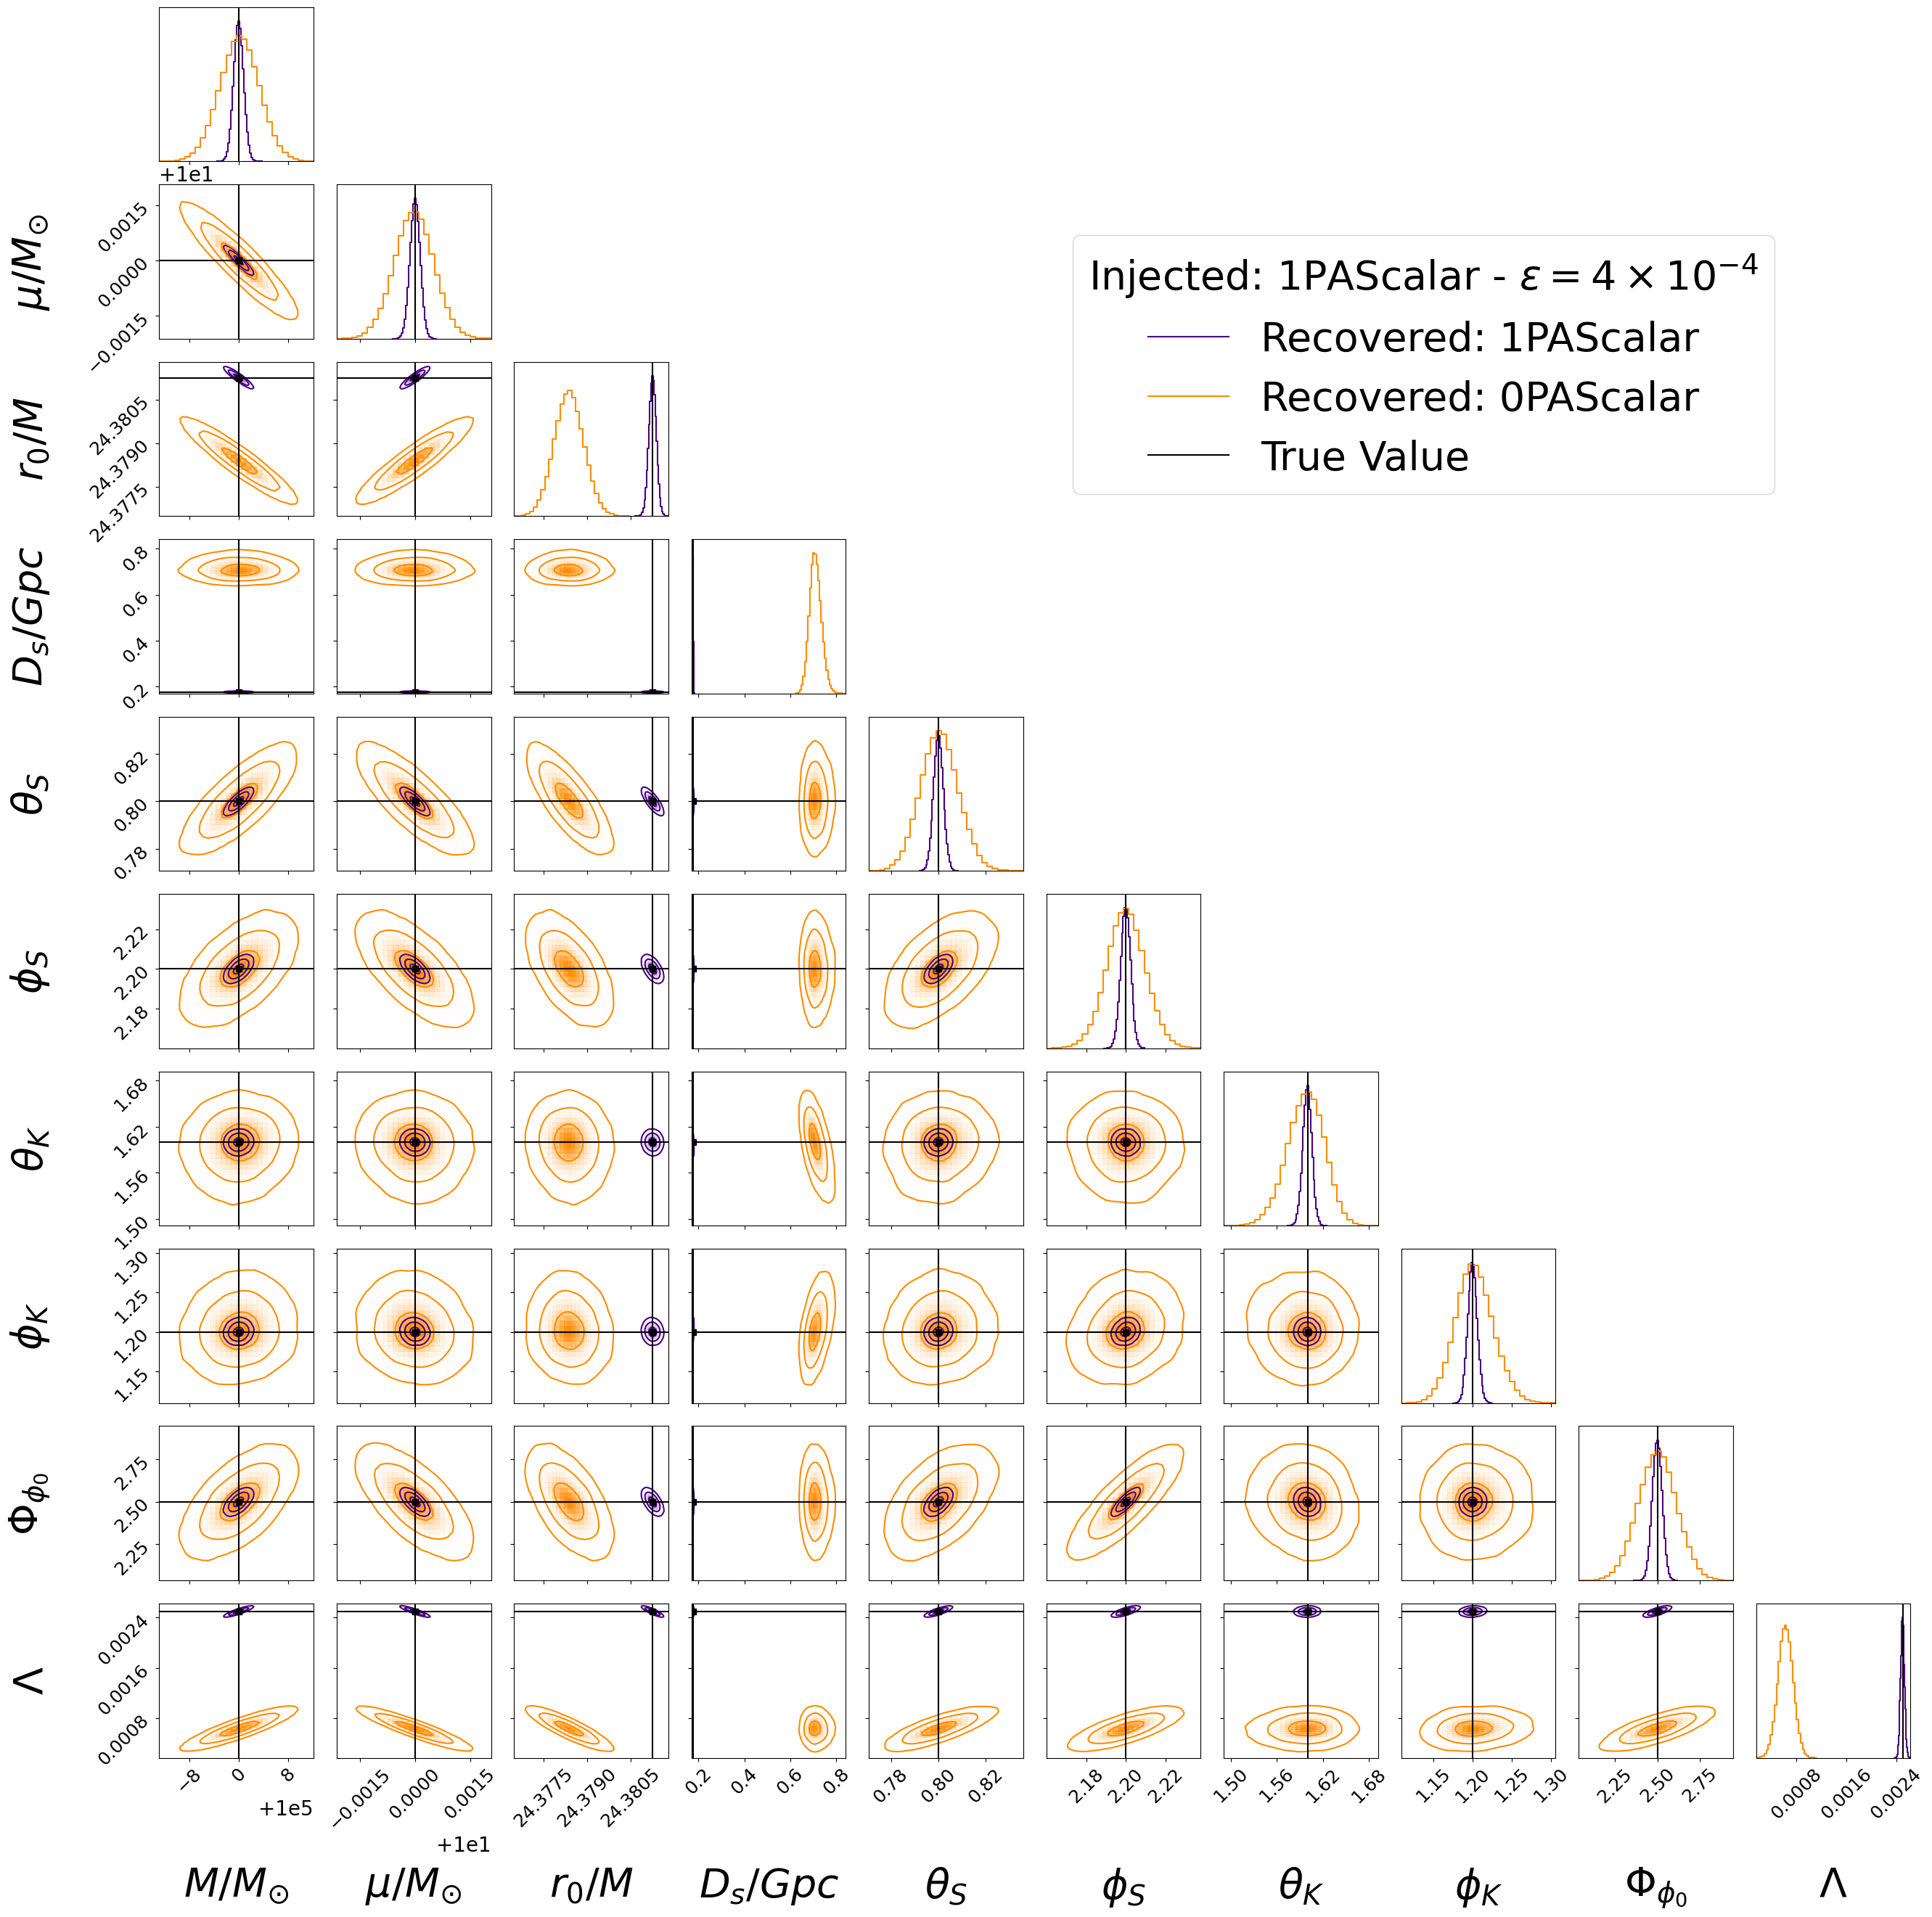

In [11]:
params_label_full = param_labels_1pa
N_params = len(param_labels_1pa)
corner_kwargs = dict(plot_datapoints=False,smooth1d=True,
                       labels=params_label_full, levels=(1 - np.exp(-0.5), 1 - np.exp(-2), 1 - np.exp(-9 / 2.)), 
                       label_kwargs=dict(fontsize=40), max_n_ticks=4,
                       show_titles=False, smooth = True, labelpad = 0.4)

samples_corner_charge_1pa = np.column_stack(burned_samples_EMRI_charge_1pa)
samples_corner_charge_0pa = np.column_stack(burned_samples_EMRI_charge_0pa)

#samples_corner_1eneg2 = np.column_stack(burned_samples_EMRI_1eneg2)

figure = corner.corner(samples_corner_charge_1pa,bins = 30, color = 'indigo', **corner_kwargs)#crimson, indigo#navy
#figure = corner.corner(samples_corner_charge,bins = 30, color = 'blue', **corner_kwargs)
weights = (len(samples_corner_charge_1pa[:,0])/len(samples_corner_charge_0pa[:,0]))*np.ones(len(samples_corner_charge_0pa[:,0]))
corner.corner(samples_corner_charge_0pa,fig = figure,bins = 30, weights = weights, color = 'darkorange', **corner_kwargs)#mediumvioletred#darkorange

axes = np.array(figure.axes).reshape((N_params, N_params))

for i in range(N_params):
    ax = axes[i, i]
    #if i == 7:
    #    mean = true_vals_EMRI_case_1[i]
    #    std = np.std(samples_corner_charge[:, i])
    #    ax.set_xlim(mean - 10*std, mean + 260*std)
    
    ax.axvline(true_vals_EMRI_1pa[i], color="k")

print("N_params=",N_params)
for yi in range(N_params):
    for xi in range(yi):
        ax = axes[yi, xi]
        #if xi == 7:
        #    mean_x = true_vals_EMRI_case_1[xi]
        #    std_x = np.std(samples_corner_charge[:, xi])
        #    ax.set_xlim(mean_x - 10*std_x, mean_x + 260*std_x)
           
        #if yi == 7:
        #     mean_y = true_vals_EMRI_case_1[yi]
         #    std_y = np.std(samples_corner_charge[:, yi])
         #    ax.set_ylim(mean_y - 10*std_y, mean_y + 260*std_y)
    
        ax.axhline(true_vals_EMRI_1pa[yi], color="k")
        ax.axvline(true_vals_EMRI_1pa[xi], color= "k")
        ax.plot(true_vals_EMRI_1pa[xi], true_vals_EMRI_1pa[yi], "sk")

for ax in figure.get_axes():
    ax.tick_params(axis='both', labelsize=18)

#red_line = mlines.Line2D([], [], color='darkblue', label=r'1PA - d=0.05 - $\chi=0.5$')
#blue_line = mlines.Line2D([], [], color='mediumvioletred', label=r'0PA - d=0.05 - $\chi=0.5$')
red_line = mlines.Line2D([], [], color='indigo', label=r'Recovered: 1PAScalar')
blue_line = mlines.Line2D([], [], color='darkorange', label=r'Recovered: 0PAScalar')
black_line = mlines.Line2D([], [], color='black', label='True Value')

plt.legend(handles=[red_line,blue_line,black_line], fontsize = 40, frameon = True, bbox_to_anchor=(0.25, N_params), loc="upper right", title = r"Injected: 1PAScalar - $\epsilon=4\times10^{-4}$", title_fontproperties = FontProperties(size = 40))
plt.subplots_adjust(left=-0.1, bottom=-0.1, right=None, top=None, wspace=0.15, hspace=0.15)

#plt.savefig("/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/figures/corner_plot_mcmc_1PAdInjVS0PAdRec_M1e5_mu4e1_charge0.05_SNR100.pdf", bbox_inches='tight')


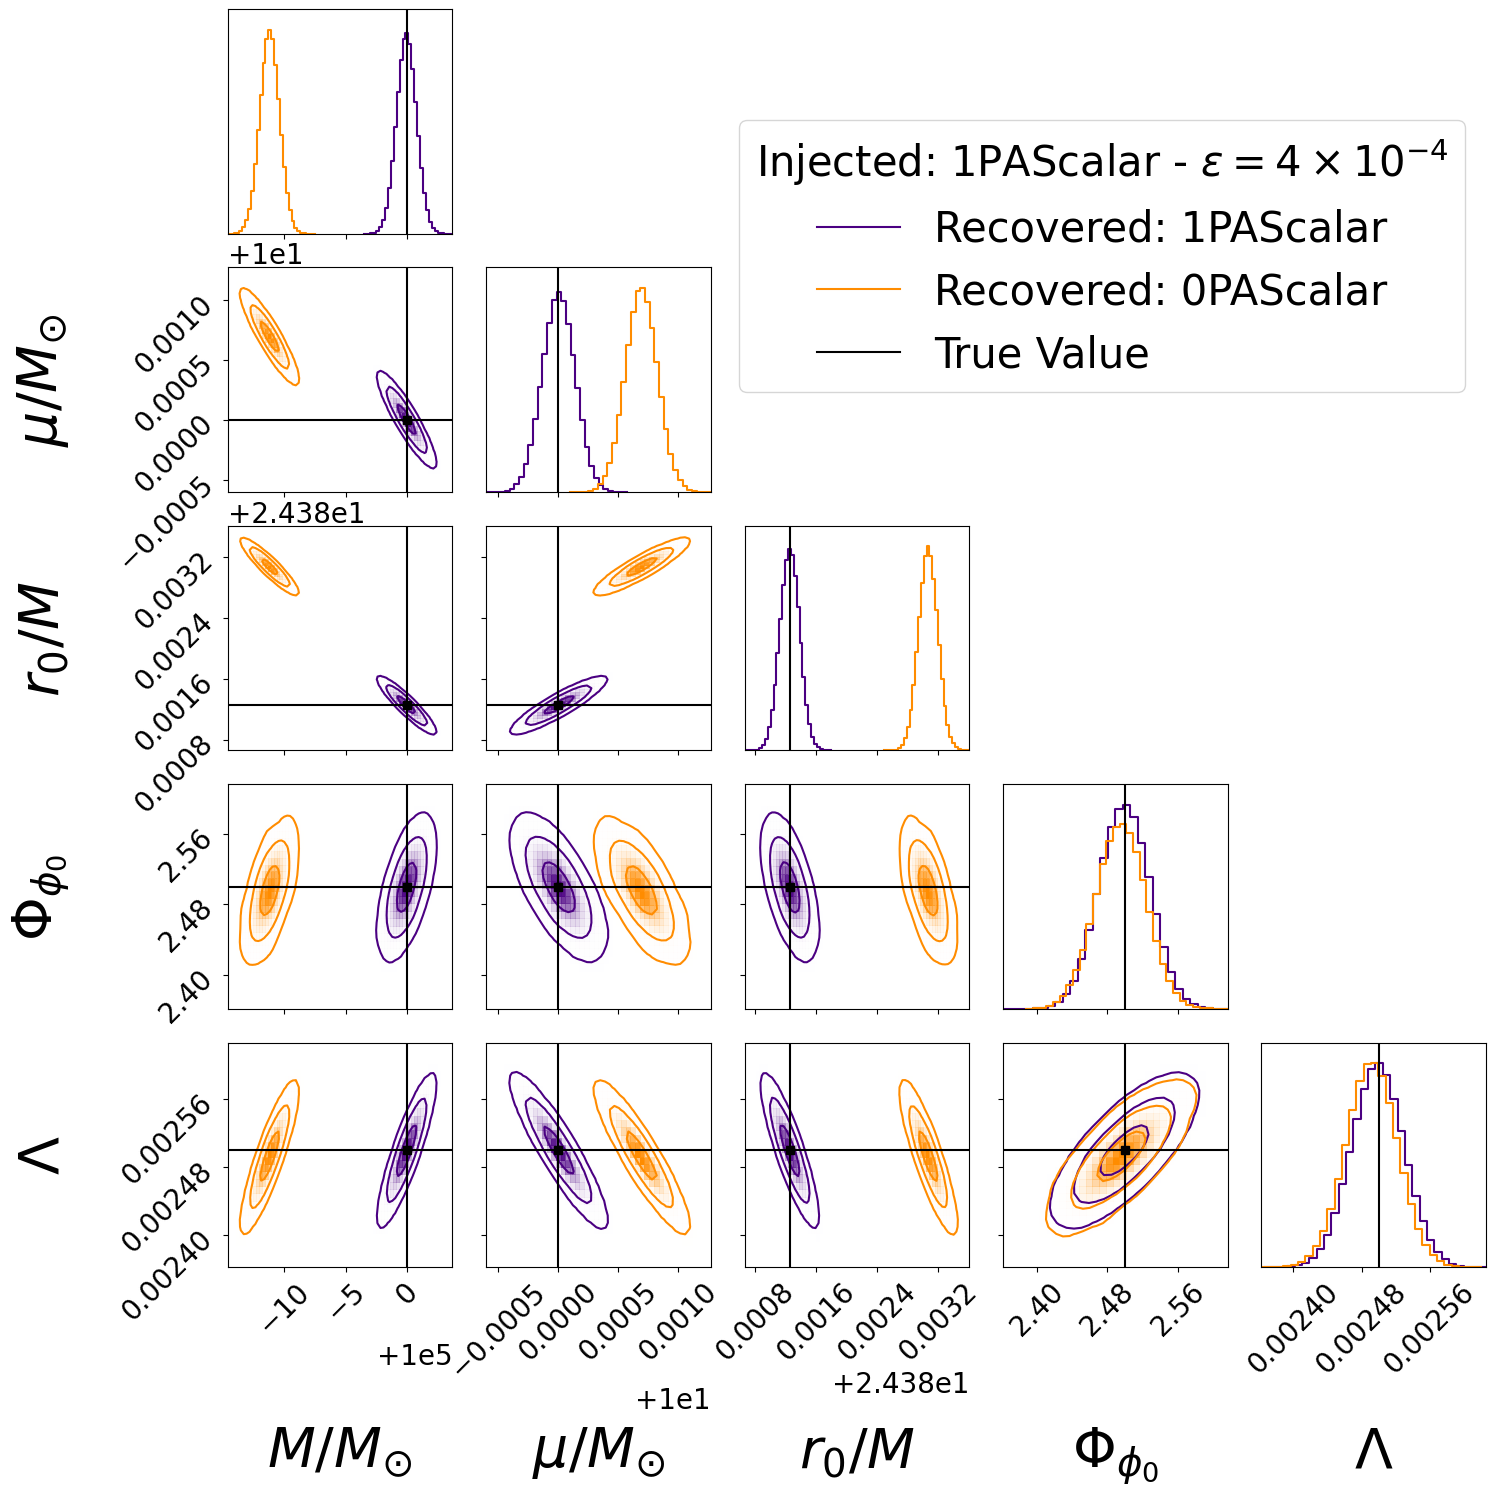

In [32]:
# === selezione parametri: primi 3 + ultimi 2 ===
idx_sel = [0, 1, 2, -2, -1]

params_label_sel = [params_label_full[i] for i in idx_sel]
true_vals_sel = true_vals_EMRI_1pa[idx_sel]

samples_corner_charge_1pa_sel = samples_corner_charge_1pa[:, idx_sel]
samples_corner_charge_0pa_sel = samples_corner_charge_0pa[:, idx_sel]

N_params_sel = len(idx_sel)

corner_kwargs_sel = dict(
    plot_datapoints=False,
    smooth1d=True,
    labels=params_label_sel,
    levels=(1 - np.exp(-0.5), 1 - np.exp(-2), 1 - np.exp(-9 / 2.)),
    label_kwargs=dict(fontsize=40),
    max_n_ticks=4,
    show_titles=False,
    smooth=True,
    labelpad=0.4
)

# === corner plot ===
figure = corner.corner(
    samples_corner_charge_1pa_sel,
    bins=30,
    color='indigo',
    **corner_kwargs_sel
)

weights = (
    len(samples_corner_charge_1pa_sel[:, 0]) /
    len(samples_corner_charge_0pa_sel[:, 0])
) * np.ones(len(samples_corner_charge_0pa_sel[:, 0]))

corner.corner(
    samples_corner_charge_0pa_sel,
    fig=figure,
    bins=30,
    weights=weights,
    color='darkorange',
    **corner_kwargs_sel
)

# === assi ===
axes = np.array(figure.axes).reshape((N_params_sel, N_params_sel))

# diagonale
for i in range(N_params_sel):
    ax = axes[i, i]
    ax.axvline(true_vals_sel[i], color="k")

# off-diagonale
for yi in range(N_params_sel):
    for xi in range(yi):
        ax = axes[yi, xi]
        ax.axhline(true_vals_sel[yi], color="k")
        ax.axvline(true_vals_sel[xi], color="k")
        ax.plot(true_vals_sel[xi], true_vals_sel[yi], "sk")

# tick size
for ax in figure.get_axes():
    ax.tick_params(axis='both', labelsize=20)

# legenda
red_line = mlines.Line2D([], [], color='indigo', label=r'Recovered: 1PAScalar')
blue_line = mlines.Line2D([], [], color='darkorange', label=r'Recovered: 0PAScalar')
black_line = mlines.Line2D([], [], color='black', label='True Value')

plt.legend(
    handles=[red_line, blue_line, black_line],
    fontsize=30,
    frameon=True,
    bbox_to_anchor=(1., 5.2),
    loc="upper right",
    title=r"Injected: 1PAScalar - $\epsilon= 4 \times 10^{-4}$",
    title_fontproperties=FontProperties(size=30)
)

plt.subplots_adjust(left=-0.1, bottom=-0.1, wspace=0.15, hspace=0.15)
#plt.savefig("/home/people/sbarsanti/scratch/MCMC_scratch/Hybrid1PAScalarVS0PAScalarResults/M50000mu10SNR200/corner_subset_1PAdInjVS0PAdRec_M5e4_mu1e1_charge0.05_SNR200.pdf", bbox_inches='tight')
#plt.savefig("/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/figures/corner_subset_1PAdInjVS0PAdRec_M1e5_mu4e1_charge0.05_SNR100.pdf", bbox_inches='tight')


In [23]:
# Estrai campioni dal cold chain (temperatura 0)
samples_flat = recast_samples_1PA[0]   # shape = (N_iter*N_walkers, N_params)

# Estrai loglike flatten foro T=0
loglike_flat = log_like_1PA[:, 0, :].reshape(-1)

# Trova il massimo
imax = np.nanargmax(loglike_flat)
best_params = samples_flat[imax]
best_loglike = loglike_flat[imax]

print("Best fit params =", best_params)
print("Best log-likelihood =", best_loglike)

loglike_initial_allwalkers = log_like_1PA[0, 0, :]
loglike_initial_mean = np.nanmean(log_like_1PA[0, 0, :])
print("loglike_initial_allwalkers=",loglike_initial_allwalkers)
print("loglike_initial_mean=",loglike_initial_mean)

idx = np.nanargmax(log_like_1PA[0,0,:])
loglike_initial_best = log_like_1PA[0,0,idx]
params_initial_best = reader_1PA.get_chain()['model_0'][0,0,idx,0,:]
print("loglike_initial_best=",loglike_initial_best)

tau = reader_1PA.get_autocorr_time()
print("tau=", tau)


Best fit params = [9.99995674e+05 5.00012634e+01 1.25689691e+01 4.64095749e-01
 7.98956104e-01 2.20686511e+00 1.59397421e+00 1.21546461e+00
 2.47449730e+00 2.34905879e-03]
Best log-likelihood = -0.0967483140659189
loglike_initial_allwalkers= [-0.10629507 -0.88395472 -6.56330069 -0.21923994 -0.28041788 -0.48445358
 -0.14402643 -1.12969046 -0.43914137 -2.85236152 -5.14617424 -1.69296331
 -1.47478227 -7.19671426 -1.47130158 -1.12827388 -0.14728208 -1.00107091
 -4.03779646 -5.26645457 -0.50601077 -5.84344967 -2.7361632  -0.14757159
 -8.95794366 -2.63242183 -2.39716127 -4.74333594 -0.98968947 -3.90562631
 -4.92580475 -2.85194503 -0.84597513 -0.87865108 -2.558428   -0.2524418
 -0.5372675  -1.21578218 -1.09158291 -6.41355546 -2.16445542 -0.98282859
 -0.09674831 -4.65594384 -0.21409261 -2.51097822 -0.75691228 -0.37340118
 -2.16837655 -0.1405058 ]
loglike_initial_mean= -2.2032149113962785
loglike_initial_best= -0.0967483140659189
tau= {'model_0': array([[66.55142412, 66.77763567, 66.37919048, 6

In [33]:
# Estrai campioni dal cold chain (temperatura 0)
samples_flat = recast_samples_0PA[0]   # shape = (N_iter*N_walkers, N_params)
print("length samples flat = ", len(samples_flat))
# Estrai loglike flatten foro T=0
loglike_flat = log_like_0PA[:, 0, :].reshape(-1)

# taglia se lunghezze non combaciano
min_len = min(len(samples_flat), len(loglike_flat))

samples_flat = samples_flat[:min_len]
loglike_flat = loglike_flat[:min_len]

# Trova il massimo
imax = np.nanargmax(loglike_flat)
best_params = samples_flat[imax]
best_loglike = loglike_flat[imax]

print("Best fit params =", best_params)
print("Best log-likelihood =", best_loglike)

loglike_initial_allwalkers = log_like_0PA[0, 0, :]
loglike_initial_mean = np.nanmean(log_like_0PA[0, 0, :])
print("loglike_initial_allwalkers=",loglike_initial_allwalkers)
print("loglike_initial_mean=",loglike_initial_mean)

idx = np.nanargmax(log_like_0PA[0,0,:])
loglike_initial_best = log_like_0PA[0,0,idx]
params_initial_best = reader_0PA.get_chain()['model_0'][0,0,idx,0,:]
print("loglike_initial_best=",loglike_initial_best)

tau = reader_0PA.get_autocorr_time()
print("tau=", tau)


length samples flat =  723552
Best fit params = [9.99892034e+04 1.00006418e+01 2.43830040e+01 1.74546132e-01
 8.00418997e-01 2.19978932e+00 1.60348602e+00 1.19943070e+00
 2.47792072e+00 2.49981020e-03]
Best log-likelihood = -0.18671121874127214
loglike_initial_allwalkers= [-36298.45409064 -36289.1912097  -36324.30567132 -36291.06285746
 -36293.46150024 -36307.48290271 -36299.73152626 -36268.93751394
 -36287.2769083  -36239.76475901 -36300.783488   -36308.73132474
 -36297.53382777 -36260.13400126 -36280.33577681 -36312.31276895
 -36286.79608696 -36307.03322382 -36318.8843241  -36265.12820234
 -36297.52495218 -36279.80176251 -36291.12748727 -36296.58267395
 -36320.75980332 -36273.494337   -36293.79944314 -36272.65709442
 -36281.71593183 -36315.46595114 -36279.17709465 -36319.6820471
 -36303.76043612 -36310.29165175 -36311.32611917 -36291.89257126
 -36286.54563562 -36281.30833062 -36305.23611713 -36309.70399588
 -36289.4928405  -36287.42633471 -36294.14864066 -36235.47255415
 -36297.17143

In [35]:
# =============================
# COMPUTING BIASES 
# =============================

# =============================
# 1) IMPORTING TRUE VALUES
# =============================
theta_true = true_vals_EMRI_1pa 

samples_flat_0pa = recast_samples_0PA[0]
samples_flat_1pa = recast_samples_1PA[0] #samples_corner_charge #

# =============================
# 2) POSTERIOR STATISTICS 
# =============================
posterior_mean_1pa   = np.mean(samples_flat_1pa, axis=0)
posterior_std_1pa    = np.std(samples_flat_1pa, axis=0, ddof=1)
posterior_mean_0pa   = np.mean(samples_flat_0pa, axis=0)
posterior_std_0pa    = np.std(samples_flat_0pa, axis=0, ddof=1)

# =============================
# 3) PRINTING RESULTS
# =============================
bias_0pa = posterior_mean_0pa - theta_true
z_0pa = bias_0pa / posterior_std_0pa   # <-- sigma dal modello A

for i in range(len(theta_true)):
    print(f"\n=== PARAMETRO {i} ===")
    print("true =", theta_true[i])
    print("mean(A) =", posterior_mean_1pa[i], " sigma(A) =", posterior_std_1pa[i])
    print("mean(B) =", posterior_mean_0pa[i])

    print("bias(B) =", bias_0pa[i], f" (z = {z_0pa[i]:.3f})")
    print(f"--> Il bias del modello B è {abs(z_0pa[i]):.3f} volte sigma(A)")



=== PARAMETRO 0 ===
true = 100000.0
mean(A) = 99999.98285790536  sigma(A) = 0.7818168056835674
mean(B) = 99988.80342309535
bias(B) = -11.19657690465101  (z = -14.419)
--> Il bias del modello B è 14.419 volte sigma(A)

=== PARAMETRO 1 ===
true = 10.0
mean(A) = 10.000003110412017  sigma(A) = 0.00013086253683658415
mean(B) = 10.000694442473064
bias(B) = 0.0006944424730637166  (z = 5.350)
--> Il bias del modello B è 5.350 volte sigma(A)

=== PARAMETRO 2 ===
true = 24.381250923881847
mean(A) = 24.381253579777  sigma(A) = 0.00012345824183974943
mean(B) = 24.38306940571585
bias(B) = 0.0018184818340039044  (z = 14.826)
--> Il bias del modello B è 14.826 volte sigma(A)

=== PARAMETRO 3 ===
true = 0.17600102119878183
mean(A) = 0.17611201536324605  sigma(A) = 0.0015025532717037548
mean(B) = 0.17607500656070757
bias(B) = 7.398536192573801e-05  (z = 0.049)
--> Il bias del modello B è 0.049 volte sigma(A)

=== PARAMETRO 4 ===
true = 0.8
mean(A) = 0.79999351899337  sigma(A) = 0.001939879228353872
me

In [31]:
# --- trova indici da labels ---
idx_L = -1
idx_mu = 1


print("idx_L =", idx_L, " idx_mu =", idx_mu)

# --- alpha posterior (derived) ---
alpha_1pa = 2.0 * np.sqrt(samples_flat_1pa[:, idx_L]) * (samples_flat_1pa[:, idx_mu]**2)
alpha_0pa = 2.0 * np.sqrt(samples_flat_0pa[:, idx_L]) * (samples_flat_0pa[:, idx_mu]**2)

sqrtalpha_1pa = np.sqrt(alpha_1pa)
sqrtalpha_0pa = np.sqrt(alpha_0pa)

alpha_true = 2.0 * np.sqrt(theta_true[idx_L]) * (theta_true[idx_mu]**2)
sqrtalpha_true = np.sqrt(alpha_true)

sqrtalpha_mean_1pa = np.mean(sqrtalpha_1pa)
sqrtalpha_std_1pa  = np.std(sqrtalpha_1pa, ddof=1)

sqrtalpha_mean_0pa = np.mean(sqrtalpha_0pa)
sqrtalpha_std_0pa  = np.std(sqrtalpha_0pa, ddof=1)

bias_sqrtalpha_0pa = sqrtalpha_mean_0pa - sqrtalpha_true

# z-score: scegli quale sigma usare (A o B)
z_sqrtalpha_0pa_B = bias_sqrtalpha_0pa / sqrtalpha_std_0pa   # in unità di sigma(B)
z_sqrtalpha_0pa_A = bias_sqrtalpha_0pa / sqrtalpha_std_1pa   # in unità di sigma(A)

print("\n=== PARAMETRO DERIVATO sqrt(alpha) ===")
print("sqrt(alpha)_true =", sqrtalpha_true)
print("mean(A=1PA) =", sqrtalpha_mean_1pa, " sigma(A) =", sqrtalpha_std_1pa)
print("mean(B=0PA) =", sqrtalpha_mean_0pa, " sigma(B) =", sqrtalpha_std_0pa)
print("bias(B) =", bias_sqrtalpha_0pa,
      f" (z_B = {z_sqrtalpha_0pa_B:.3f}, z_A = {z_sqrtalpha_0pa_A:.3f})")


mu_mean = np.mean(samples_flat_0pa[:, idx_mu])
L_mean  = np.mean(samples_flat_0pa[:, idx_L])

mu_true = theta_true[idx_mu]
L_true  = theta_true[idx_L]

bias_mu = mu_mean - mu_true
bias_L  = L_mean - L_true
print("bias_mu=", bias_mu)
print("bias_L=", bias_L)

term_mu = np.sqrt(2) * (L_true**0.25) * bias_mu
term_L  = (np.sqrt(2)/4) * mu_true * (L_true**(-0.75)) * bias_L

print("Contributo bias da mu:", term_mu)
print("Contributo bias da Lambda:", term_L)
print("Somma approx:", term_mu + term_L)
print("Bias reale sqrt(alpha):", bias_sqrtalpha_0pa)


idx_L = -1  idx_mu = 1

=== PARAMETRO DERIVATO sqrt(alpha) ===
sqrt(alpha)_true = 3.1622776601683795
mean(A=1PA) = 3.161999101245811  sigma(A) = 0.00930065029844611
mean(B=0PA) = 3.1599785024814024  sigma(B) = 0.009195394126306426
bias(B) = -0.0022991576869770824  (z_B = -0.250, z_A = -0.247)
bias_mu= 0.0006939149250033694
bias_L= -7.8263437600745e-06
Contributo bias da mu: 0.00021943516653955719
Contributo bias da Lambda: -0.0024749072033281782
Somma approx: -0.002255472036788621
Bias reale sqrt(alpha): -0.0022991576869770824


## 1PAScalar VS 1PAGR and 0PAGR

In [4]:


file_path = "/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/data/"
file_path_charge_1PAScalar = file_path + "samples_1PAdInj1PAdRec_M100000.0_mu10.0_p024.378402244813003_Lambda0.0006250000000000001_SNR50_dist0.7041716088918832_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"
file_path_charge_1PAGR = file_path + "samples_1PAdInj1PAGRRec_M100000.0_mu10.0_p024.378402244813003_Lambda0.0006250000000000001_SNR50_dist0.7041716088923775_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"
file_path_charge_0PAGR = file_path + "samples_1PAdInj0PAGRRec_M100000.0_mu10.0_p024.378402244813003_Lambda0.0006250000000000001_SNR50_dist0.7041716088918832_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"

burned_samples_dict_EMRI_charge_1PAScalar, param_labels_1PAScalar, true_vals_EMRI_1PAScalar =  load_samples_h5(file_path_charge_1PAScalar)
burned_samples_dict_EMRI_charge_1PAGR, param_labels_1PAGR, true_vals_EMRI_1PAGR =  load_samples_h5(file_path_charge_1PAGR)
burned_samples_dict_EMRI_charge_0PAGR, param_labels_0PAGR, true_vals_EMRI_0PAGR =  load_samples_h5(file_path_charge_0PAGR)

burned_samples_EMRI_charge_1PAScalar = list(burned_samples_dict_EMRI_charge_1PAScalar.values())
burned_samples_EMRI_charge_1PAGR = list(burned_samples_dict_EMRI_charge_1PAGR.values())
burned_samples_EMRI_charge_0PAGR = list(burned_samples_dict_EMRI_charge_0PAGR.values())


N_params= 9


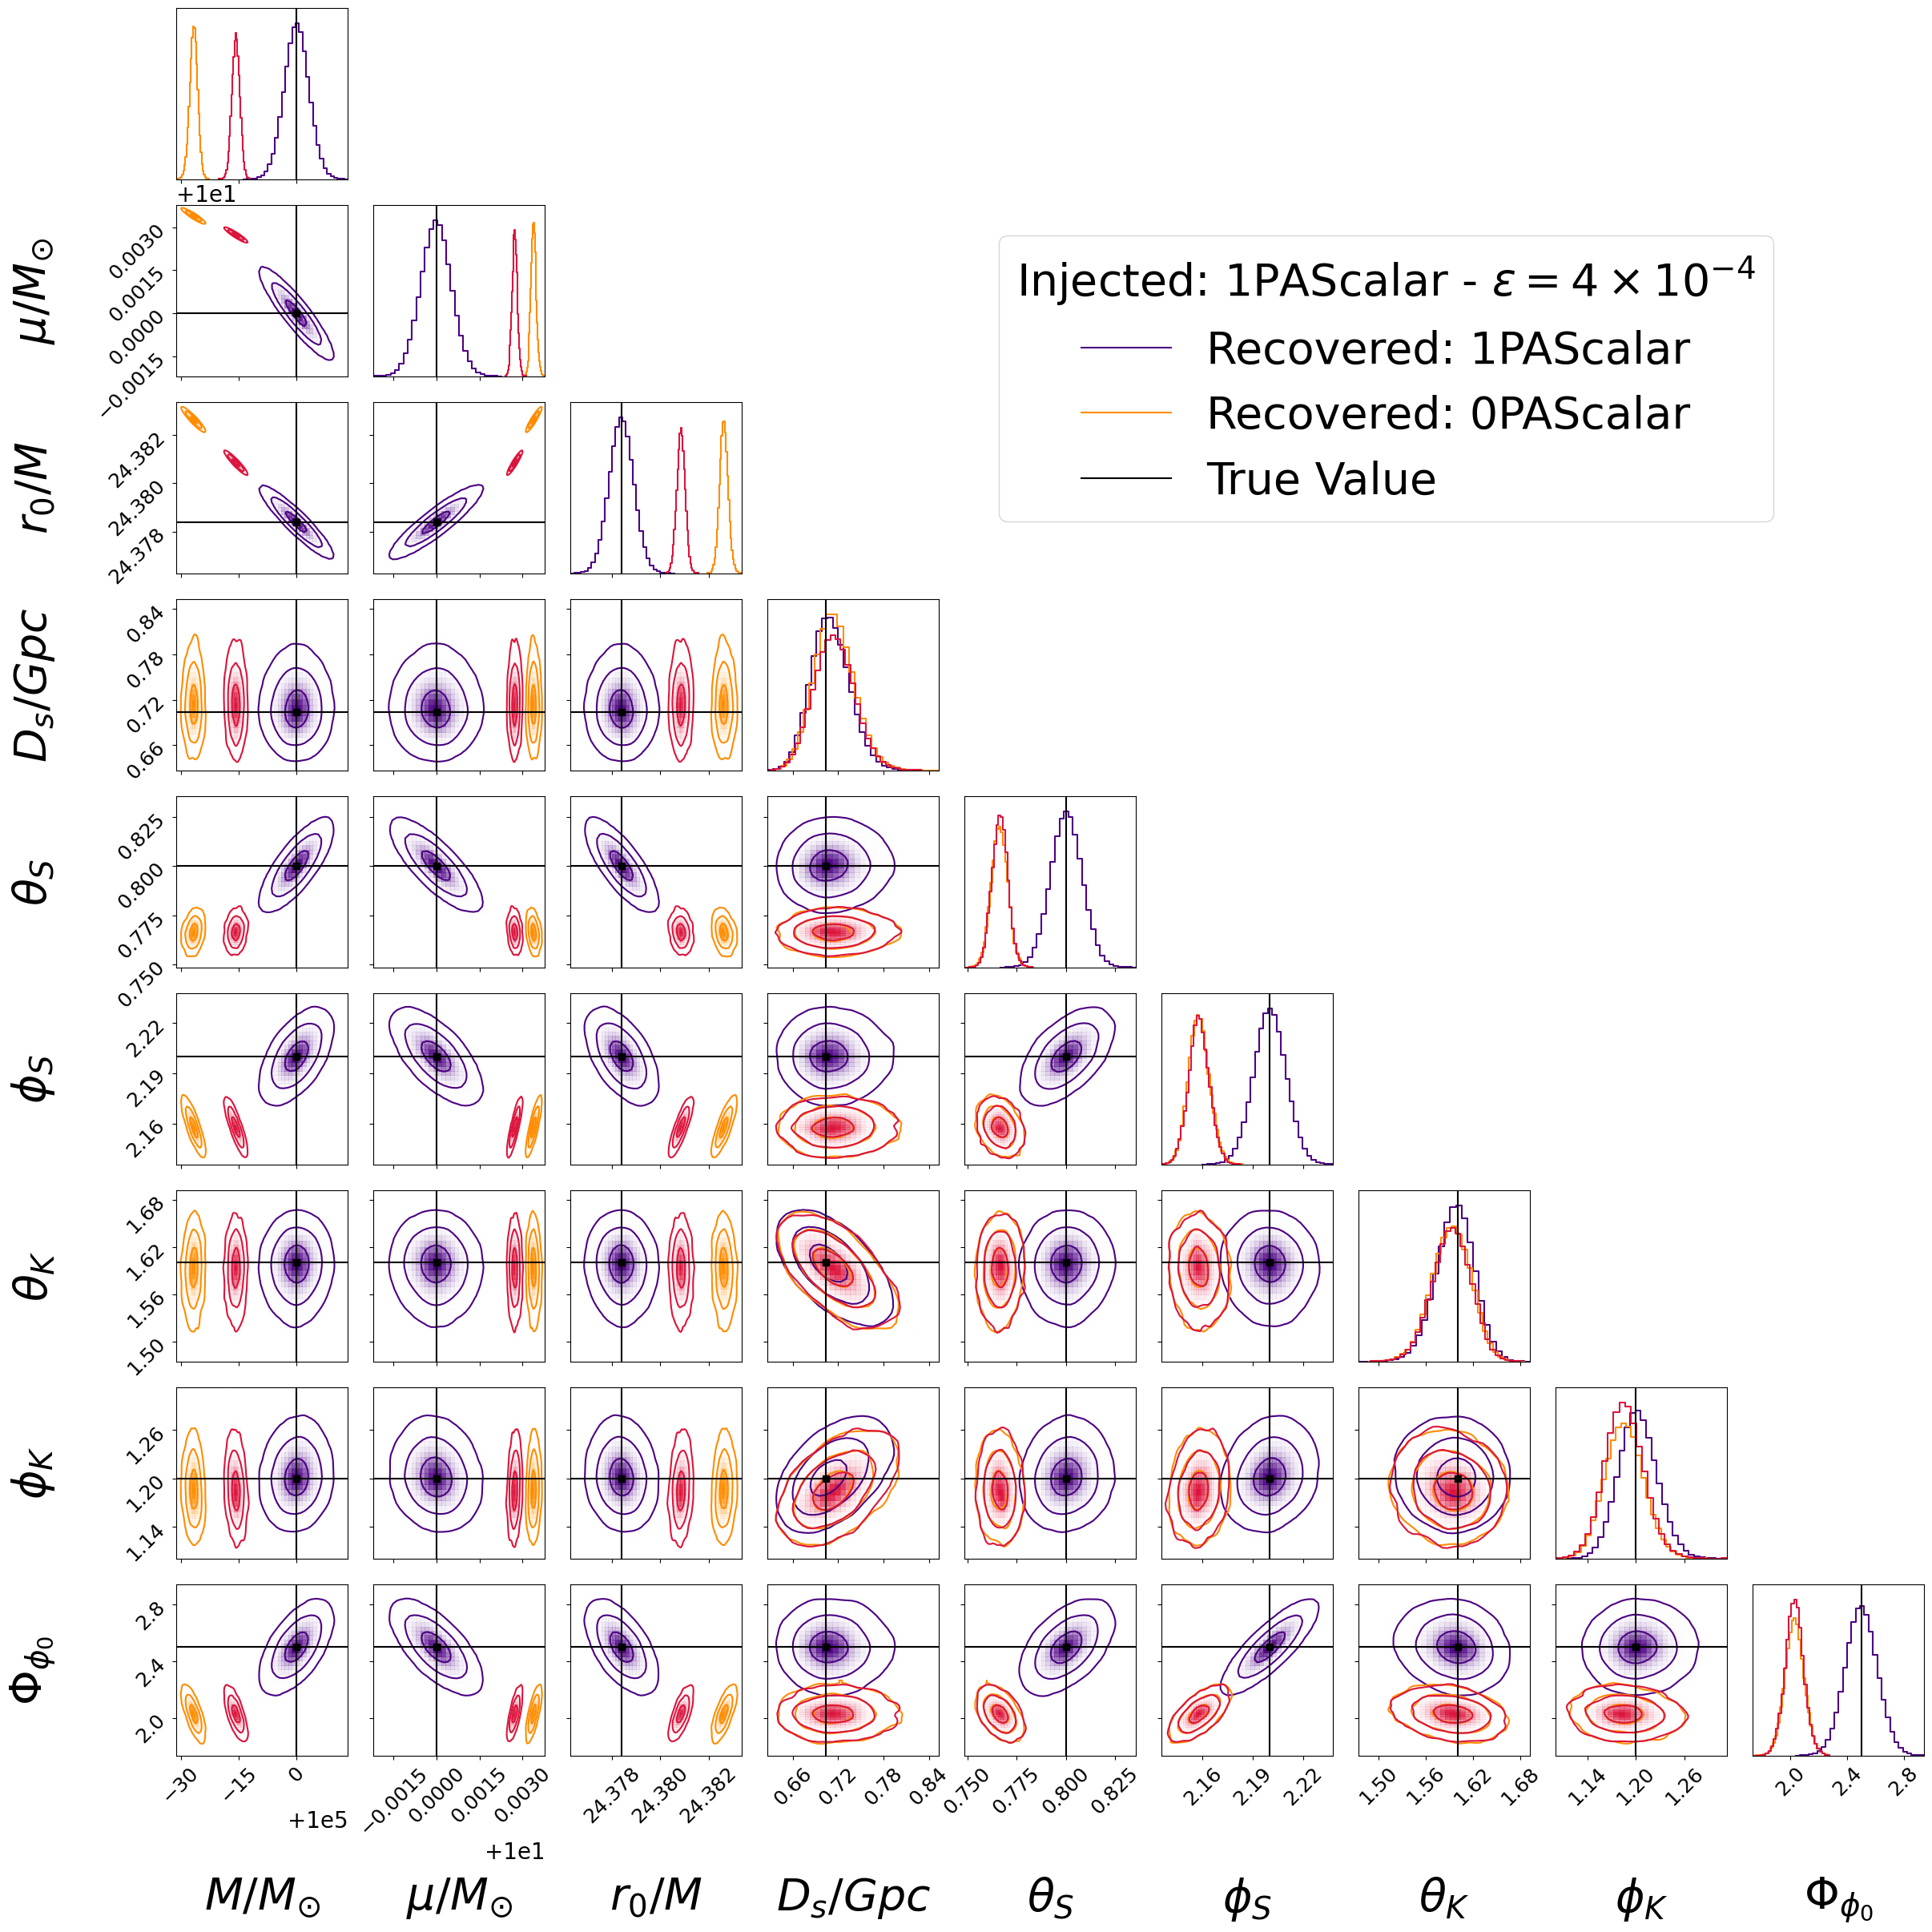

In [5]:
params_label_full = param_labels_1PAScalar[:-1]
true_vals_EMRI_1pa = true_vals_EMRI_1PAScalar[:-1]
N_params = len(params_label_full)
corner_kwargs = dict(plot_datapoints=False,smooth1d=True,
                       labels=params_label_full, levels=(1 - np.exp(-0.5), 1 - np.exp(-2), 1 - np.exp(-9 / 2.)), 
                       label_kwargs=dict(fontsize=40), max_n_ticks=4,
                       show_titles=False, smooth = True, labelpad = 0.4)

samples_corner_charge_1PAScalar = np.column_stack(burned_samples_EMRI_charge_1PAScalar)
samples_corner_charge_1PAScalar = samples_corner_charge_1PAScalar[:, :-1]
samples_corner_charge_1PAGR = np.column_stack(burned_samples_EMRI_charge_1PAGR)
samples_corner_charge_0PAGR = np.column_stack(burned_samples_EMRI_charge_0PAGR)

#samples_corner_1eneg2 = np.column_stack(burned_samples_EMRI_1eneg2)

figure = corner.corner(samples_corner_charge_1PAScalar,bins = 30, color = 'indigo', **corner_kwargs)#crimson, indigo#navy
#figure = corner.corner(samples_corner_charge,bins = 30, color = 'blue', **corner_kwargs)
weights = (len(samples_corner_charge_1PAScalar[:,0])/len(samples_corner_charge_0PAGR[:,0]))*np.ones(len(samples_corner_charge_0PAGR[:,0]))
corner.corner(samples_corner_charge_0PAGR,fig = figure,bins = 30, weights = weights, color = 'darkorange', **corner_kwargs)#mediumvioletred#darkorange
weights = (len(samples_corner_charge_1PAScalar[:,0])/len(samples_corner_charge_1PAGR[:,0]))*np.ones(len(samples_corner_charge_1PAGR[:,0]))
corner.corner(samples_corner_charge_1PAGR,fig = figure,bins = 30, weights = weights, color = 'crimson', **corner_kwargs)#mediumvioletred#darkorange


axes = np.array(figure.axes).reshape((N_params, N_params))

for i in range(N_params):
    ax = axes[i, i]
    #if i == 7:
    #    mean = true_vals_EMRI_case_1[i]
    #    std = np.std(samples_corner_charge[:, i])
    #    ax.set_xlim(mean - 10*std, mean + 260*std)
    
    ax.axvline(true_vals_EMRI_1pa[i], color="k")

print("N_params=",N_params)
for yi in range(N_params):
    for xi in range(yi):
        ax = axes[yi, xi]
        #if xi == 7:
        #    mean_x = true_vals_EMRI_case_1[xi]
        #    std_x = np.std(samples_corner_charge[:, xi])
        #    ax.set_xlim(mean_x - 10*std_x, mean_x + 260*std_x)
           
        #if yi == 7:
        #     mean_y = true_vals_EMRI_case_1[yi]
         #    std_y = np.std(samples_corner_charge[:, yi])
         #    ax.set_ylim(mean_y - 10*std_y, mean_y + 260*std_y)
    
        ax.axhline(true_vals_EMRI_1pa[yi], color="k")
        ax.axvline(true_vals_EMRI_1pa[xi], color= "k")
        ax.plot(true_vals_EMRI_1pa[xi], true_vals_EMRI_1pa[yi], "sk")

for ax in figure.get_axes():
    ax.tick_params(axis='both', labelsize=18)

#red_line = mlines.Line2D([], [], color='darkblue', label=r'1PA - d=0.05 - $\chi=0.5$')
#blue_line = mlines.Line2D([], [], color='mediumvioletred', label=r'0PA - d=0.05 - $\chi=0.5$')
red_line = mlines.Line2D([], [], color='indigo', label=r'Recovered: 1PAScalar')
blue_line = mlines.Line2D([], [], color='darkorange', label=r'Recovered: 0PAScalar')
black_line = mlines.Line2D([], [], color='black', label='True Value')

plt.legend(handles=[red_line,blue_line,black_line], fontsize = 40, frameon = True, bbox_to_anchor=(0.25, N_params), loc="upper right", title = r"Injected: 1PAScalar - $\epsilon=4\times10^{-4}$", title_fontproperties = FontProperties(size = 40))
plt.subplots_adjust(left=-0.1, bottom=-0.1, right=None, top=None, wspace=0.15, hspace=0.15)

#plt.savefig("/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/figures/corner_plot_mcmc_1PAdInjVS0PAdRec_M1e5_mu4e1_charge0.05_SNR100.pdf", bbox_inches='tight')


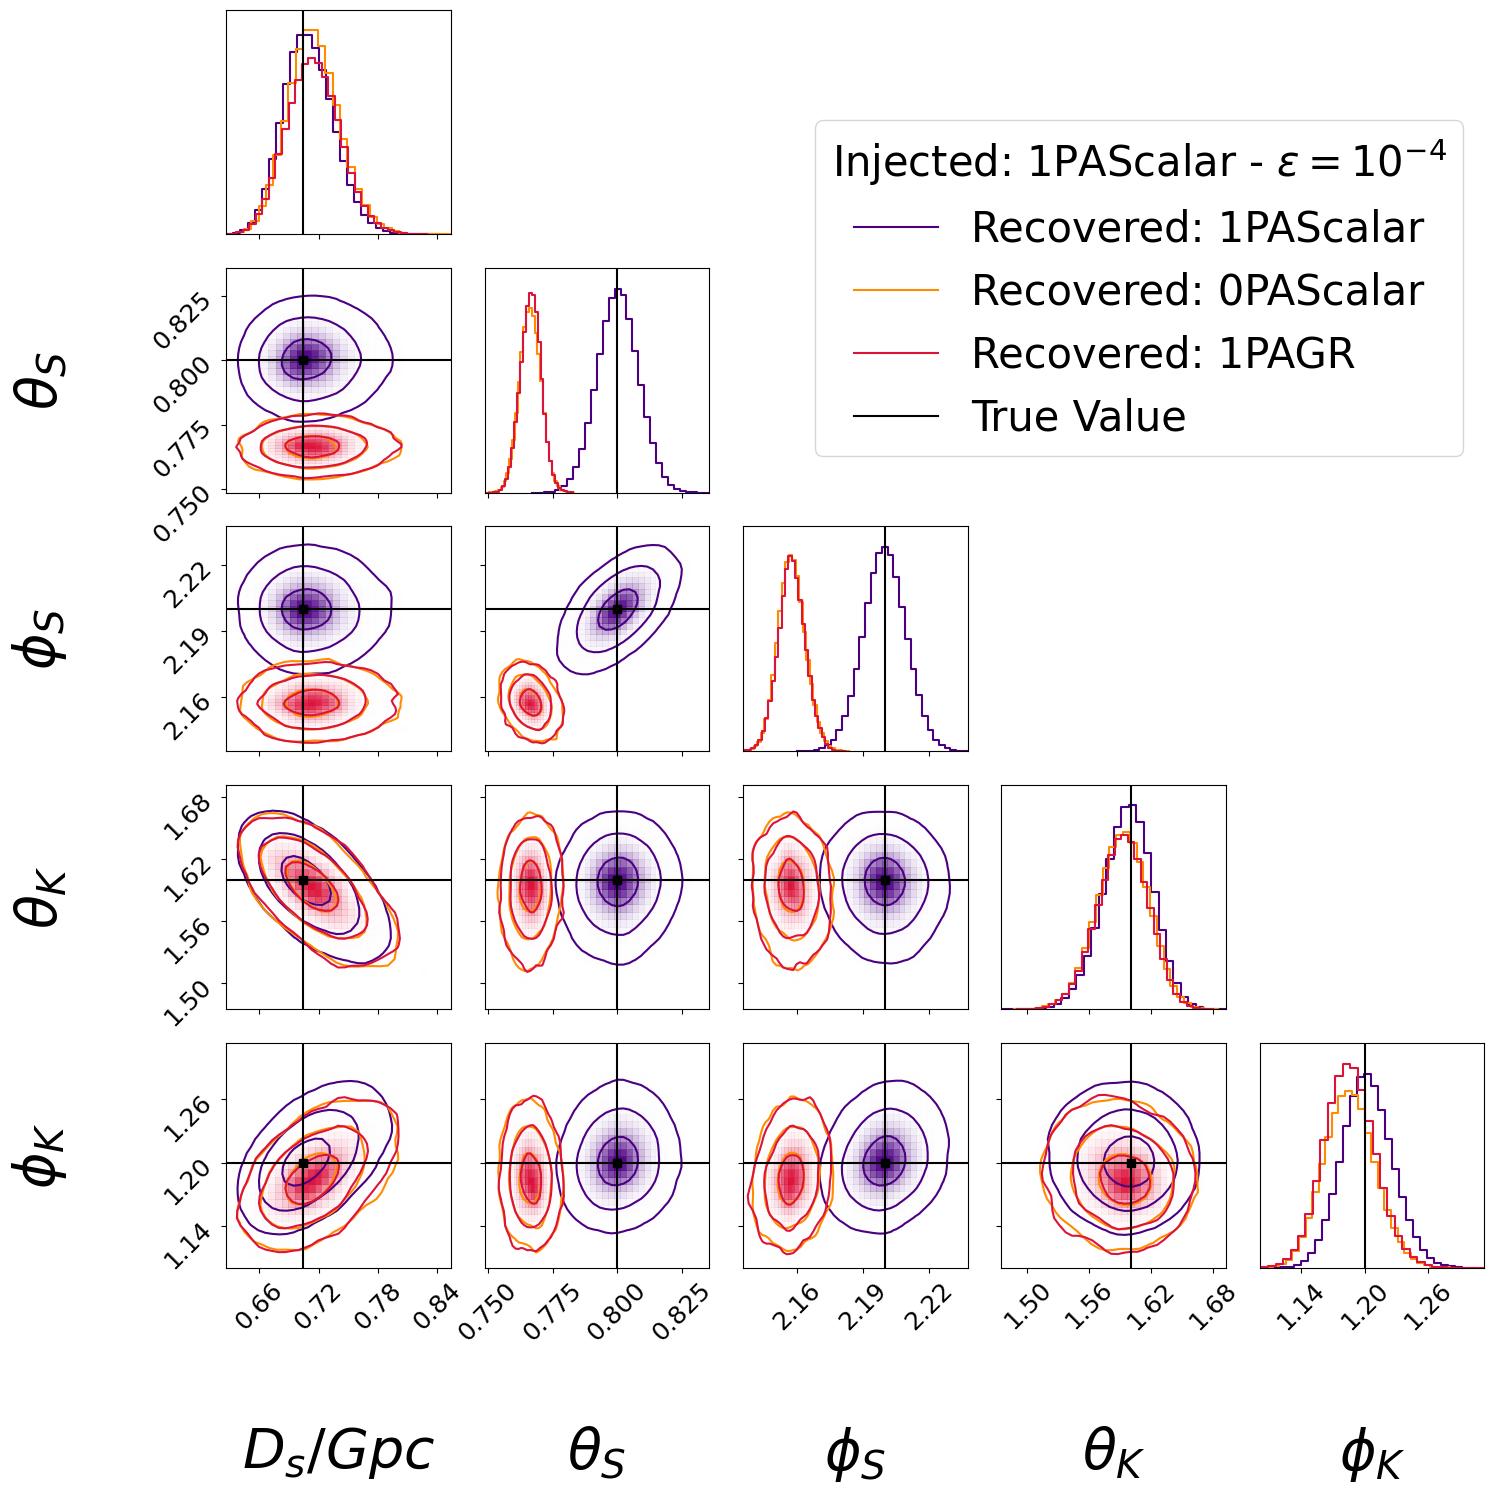

In [17]:
# primo corner: primi 3 parametri + ultimo
idx_corner_1 = [0, 1, 2, 8]

# secondo corner: gli altri 5 parametri
idx_corner_2 = [3, 4, 5, 6, 7]

def make_corner_plot(indices, filename=None):
    labels = [params_label_full[i] for i in indices]
    true_vals = true_vals_EMRI_1pa[indices]

    samples_1PAScalar = samples_corner_charge_1PAScalar[:, indices]
    samples_0PAGR = samples_corner_charge_0PAGR[:, indices]
    samples_1PAGR = samples_corner_charge_1PAGR[:, indices]

    N = len(indices)

    corner_kwargs_split = dict(
        plot_datapoints=False,
        smooth1d=True,
        labels=labels,
        levels=(1 - np.exp(-0.5), 1 - np.exp(-2), 1 - np.exp(-9 / 2.)),
        label_kwargs=dict(fontsize=40),
        max_n_ticks=4,
        show_titles=False,
        smooth=True,
        labelpad=0.4
    )

    fig = corner.corner(
        samples_1PAScalar,
        bins=30,
        color='indigo',
        **corner_kwargs_split
    )

    weights = (
        len(samples_1PAScalar[:, 0]) / len(samples_0PAGR[:, 0])
    ) * np.ones(len(samples_0PAGR[:, 0]))

    corner.corner(
        samples_0PAGR,
        fig=fig,
        bins=30,
        weights=weights,
        color='darkorange',
        **corner_kwargs_split
    )

    weights = (
        len(samples_1PAScalar[:, 0]) / len(samples_1PAGR[:, 0])
    ) * np.ones(len(samples_1PAGR[:, 0]))

    corner.corner(
        samples_1PAGR,
        fig=fig,
        bins=30,
        weights=weights,
        color='crimson',
        **corner_kwargs_split
    )

    axes = np.array(fig.axes).reshape((N, N))

    for i in range(N):
        ax = axes[i, i]
        ax.axvline(true_vals[i], color="k")

    for yi in range(N):
        for xi in range(yi):
            ax = axes[yi, xi]
            ax.axhline(true_vals[yi], color="k")
            ax.axvline(true_vals[xi], color="k")
            ax.plot(true_vals[xi], true_vals[yi], "sk")

    for ax in fig.get_axes():
        ax.tick_params(axis='both', labelsize=18)

    red_line = mlines.Line2D([], [], color='indigo', label=r'Recovered: 1PAScalar')
    blue_line = mlines.Line2D([], [], color='darkorange', label=r'Recovered: 0PAScalar')
    crimson_line = mlines.Line2D([], [], color='crimson', label=r'Recovered: 1PAGR')
    black_line = mlines.Line2D([], [], color='black', label='True Value')

    plt.legend(
        handles=[red_line, blue_line, crimson_line, black_line],
        fontsize=30,
        frameon=True,
        bbox_to_anchor=(1.0, 5.2),
        loc="upper right",
        title=r"Injected: 1PAScalar - $\epsilon=10^{-4}$",
        title_fontproperties=FontProperties(size=30)
    )


    plt.subplots_adjust(
        left=-0.1,
        bottom=-0.1,
        wspace=0.15,
        hspace=0.15
    )

    if filename is not None:
        plt.savefig(filename, bbox_inches='tight')

    return fig


#fig1 = make_corner_plot(
#    idx_corner_1,
#    filename="corner_first3_plus_last.pdf"
#)
#
fig2 = make_corner_plot(
    idx_corner_2,
    filename="corner_middle5.pdf"
)


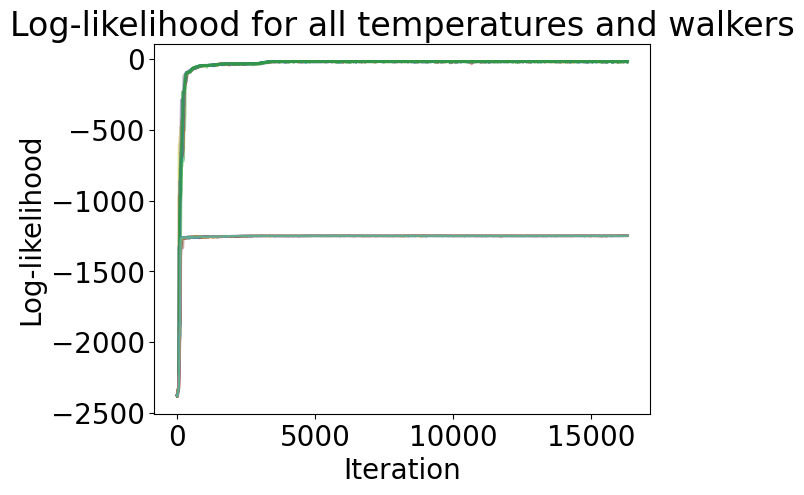

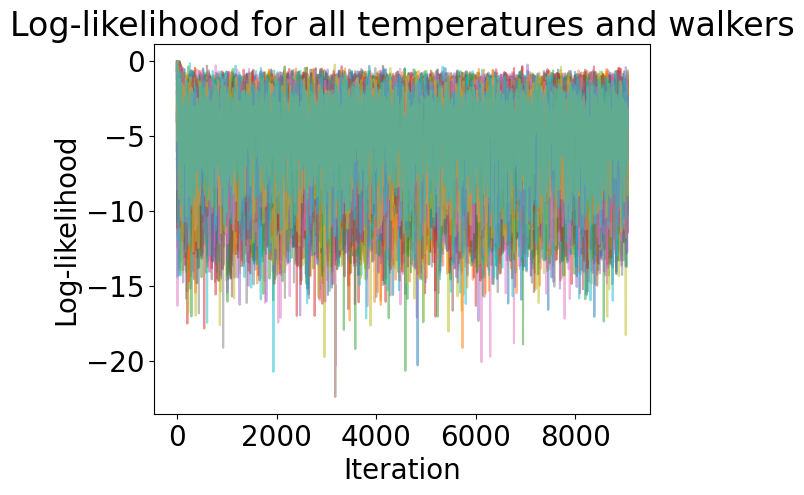

/home/people/sbarsanti/scratch/MCMC_scratch/final/


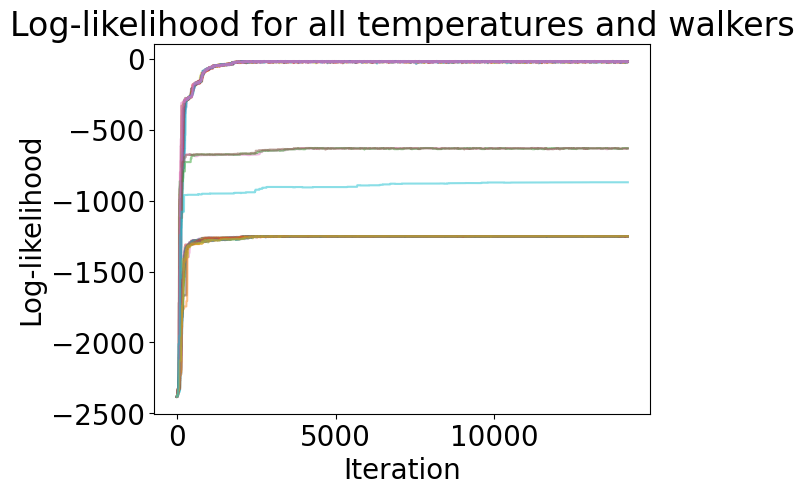

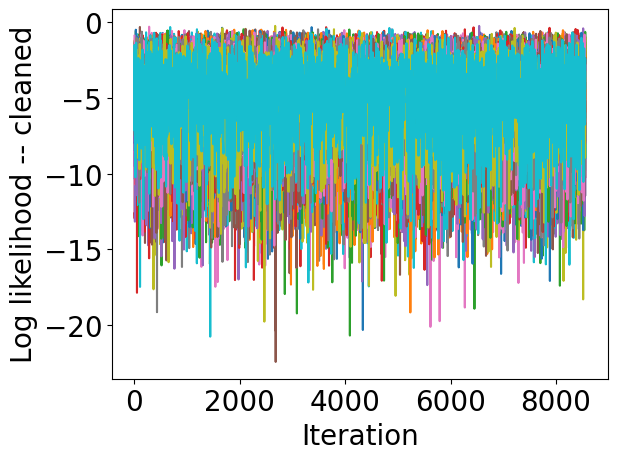

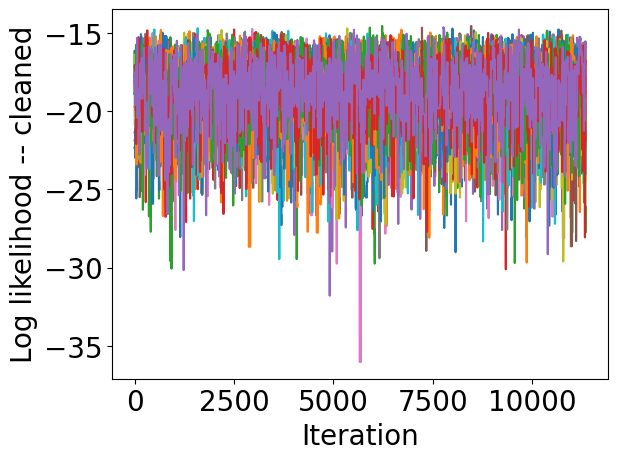

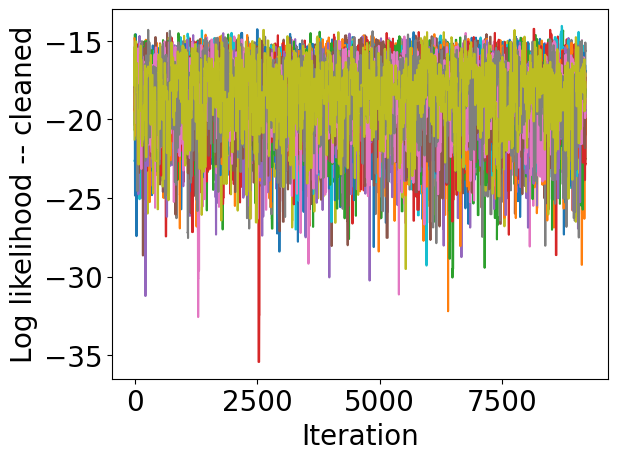

Best log-likelihood 0PA= -14.04718462561895
loglike_initial_allwalkers 0PA= [-2382.82457324 -2382.85526769 -2381.71758002 -2382.88993116
 -2382.85530825 -2382.39583623 -2382.80495276 -2382.94701661
 -2382.93551975 -2382.34898191 -2382.29252413 -2382.62174898
 -2382.66978767 -2382.96846694 -2383.0577475  -2381.98710233
 -2382.80224888 -2382.51257417 -2382.12559371 -2383.01277731
 -2382.79024854 -2382.9910072  -2382.62647113 -2382.72133237
 -2382.27059634 -2383.0973695  -2382.57651053 -2382.95329111
 -2382.98147666 -2381.16535453 -2382.98832799 -2381.59017531
 -2382.76220748 -2382.66824051 -2382.56662148 -2382.93433941
 -2383.05095427 -2383.0860089  -2382.70194905 -2382.36697437
 -2382.57447795 -2382.9140218  -2382.78282134 -2382.51707832
 -2382.84485439 -2382.98505145 -2382.83457798 -2382.77789933
 -2382.33571143 -2382.78182863]
loglike_initial_mean 0PA= -2382.6572663702923
loglike_initial_best 0PA= -2381.165354529194
tau= {'model_0': array([[93.46939852, 92.14981545, 93.33209397, 90.19

In [70]:
#################################################### 1PAd Inj VS 1/0PA GR Rec (systematics) - d=0.025 ###################à#######################
file_path="/home/people/sbarsanti/scratch/MCMC_scratch/final/"
#F#58446#
file_name_1PAScalar ="MCMC_samps_1PAdInj1PAdRec_M100000.0_mu10.0_p024.378402244813003_Lambda0.0006250000000000001_SNR50_dist0.7041716088918832_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5" 
#F#68954#
file_name_1PA ="MCMC_samps_1PAdInj1PAGRRec_M100000.0_mu10.0_p024.378402244813003_Lambda0.0006250000000000001_SNR50_dist0.7041716088923775_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"
#F#75205#
file_name_0PA ="MCMC_samps_1PAdInj0PAGRRec_M100000.0_mu10.0_p024.378402244813003_Lambda0.0006250000000000001_SNR50_dist0.7041716088918832_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"


samples_after_burnin_1PA, reader_1PA, log_like_1PA, N_params_1PA, N_temps_1PA = analyse_samples(file_path+file_name_1PA, discard= 0, plot_log_like = True, 
                                                                            trace_plot = False)

samples_after_burnin_1PAScalar, reader_1PAScalar, log_like_1PAScalar, N_params_1PAScalar, N_temps_1PAScalar = analyse_samples(file_path+file_name_1PAScalar, discard= 0, plot_log_like = True, 
                                                                            trace_plot = False)

print(file_path)
samples_after_burnin_0PA, reader_0PA, log_like_0PA, N_params_0PA, N_temps_0PA = analyse_samples(file_path+file_name_0PA, discard= 0, plot_log_like = True, 
                                                                            trace_plot = False)

filtered_log_like_1PAScalar, recast_samples_1PAScalar= remove_bad_walkers(reader_1PAScalar, log_like_threshold = -1000, burn =500, plot_log_like = True)
filtered_log_like_1PA, recast_samples_1PA= remove_bad_walkers(reader_1PA, log_like_threshold = -1000, burn =5000, plot_log_like = True)
filtered_log_like_0PA, recast_samples_0PA= remove_bad_walkers(reader_0PA, log_like_threshold = -400, burn =5000, plot_log_like = True)


# Estrai campioni dal cold chain (temperatura 0)
samples_flat = recast_samples_0PA[0]   # shape = (N_iter*N_walkers, N_params)
loglike_flat = filtered_log_like_0PA[:, 0, :].reshape(-1)
# taglia se lunghezze non combaciano
min_len = min(len(samples_flat), len(loglike_flat))

samples_flat = samples_flat[:min_len]
loglike_flat = loglike_flat[:min_len]

# Trova il massimo
imax = np.nanargmax(loglike_flat)
best_params = samples_flat[imax]
best_loglike = loglike_flat[imax]

#print("Best fit params =", best_params)
print("Best log-likelihood 0PA=", best_loglike)

loglike_initial_allwalkers = log_like_0PA[0, 0, :]
loglike_initial_mean = np.nanmean(log_like_0PA[0, 0, :])
print("loglike_initial_allwalkers 0PA=",loglike_initial_allwalkers)
print("loglike_initial_mean 0PA=",loglike_initial_mean)

idx = np.nanargmax(log_like_0PA[0,0,:])
loglike_initial_best = log_like_0PA[0,0,idx]
params_initial_best = reader_0PA.get_chain()['model_0'][0,0,idx,0,:]
print("loglike_initial_best 0PA=",loglike_initial_best)

tau = reader_0PA.get_autocorr_time()
print("tau=", tau)

###### 1PA ######
samples_flat = recast_samples_1PA[0]   # shape = (N_iter*N_walkers, N_params)
loglike_flat = filtered_log_like_1PA[:, 0, :].reshape(-1)

# Trova il massimo
imax = np.nanargmax(loglike_flat)
best_params = samples_flat[imax]
best_loglike = loglike_flat[imax]

#print("Best fit params =", best_params)
print("Best log-likelihood 1PA =", best_loglike)

loglike_initial_allwalkers = log_like_1PA[0, 0, :]
loglike_initial_mean = np.nanmean(log_like_1PA[0, 0, :])
print("loglike_initial_allwalkers 1PA=",loglike_initial_allwalkers)
print("loglike_initial_mean 1PA=",loglike_initial_mean)

idx = np.nanargmax(log_like_1PA[0,0,:])
loglike_initial_best = log_like_1PA[0,0,idx]
params_initial_best = reader_1PA.get_chain()['model_0'][0,0,idx,0,:]
print("loglike_initial_best 1PA=",loglike_initial_best)

tau = reader_1PA.get_autocorr_time()
print("tau 1pA=", tau)

In [79]:
# =============================
# COMPUTING BIASES 
# =============================
print("###### 0PA #######")
# =============================
# 1) IMPORTING TRUE VALUES
# =============================
theta_true = true_vals_EMRI_1pa 

samples_flat_0pa = recast_samples_0PA[0]
samples_flat_1pa = recast_samples_1PA[0]
samples_flat_1pascalar = recast_samples_1PAScalar[0]
samples_flat_1pascalar = samples_flat_1pascalar[:, :-1]

# =============================
# 2) POSTERIOR STATISTICS 
# =============================
posterior_mean_1pascalar   = np.mean(samples_flat_1pascalar, axis=0)
posterior_std_1pascalar    = np.std(samples_flat_1pascalar, axis=0, ddof=1)
posterior_mean_1pa   = np.mean(samples_flat_1pa, axis=0)
posterior_std_1pa    = np.std(samples_flat_1pa, axis=0, ddof=1)
posterior_mean_0pa   = np.mean(samples_flat_0pa, axis=0)
posterior_std_0pa    = np.std(samples_flat_0pa, axis=0, ddof=1)

# =============================
# 3) PRINTING RESULTS
# =============================
bias_0pa = posterior_mean_0pa - theta_true
z_0pa = bias_0pa / posterior_std_0pa   # <-- sigma dal modello B

for i in range(len(theta_true)):
    print(f"\n=== PARAMETRO {i} ===")
    print("true =", theta_true[i])
    print("mean(A) =", posterior_mean_1pascalar[i], " sigma(A) =", posterior_std_1pascalar[i])
    print("mean(B) =", posterior_mean_0pa[i])

    print("bias(B) =", bias_0pa[i], f" (z = {z_0pa[i]:.3f})")
    print(f"--> Il bias del modello B è {abs(z_0pa[i]):.3f} volte sigma(B)")



# =============================
# COMPUTING BIASES 
# =============================
print("###### 1PA #######")

bias_1pa = posterior_mean_1pa - theta_true
z_1pa = bias_1pa / posterior_std_1pa   # <-- sigma dal modello B

for i in range(len(theta_true)):
    print(f"\n=== PARAMETRO {i} ===")
    print("true =", theta_true[i])
    print("mean(A) =", posterior_mean_1pascalar[i], " sigma(A) =", posterior_std_1pascalar[i])
    print("mean(B) =", posterior_mean_1pa[i])

    print("bias(B) =", bias_1pa[i], f" (z = {z_1pa[i]:.3f})")
    print(f"--> Il bias del modello B è {abs(z_1pa[i]):.3f} volte sigma(B)")
    


###### 0PA #######

=== PARAMETRO 0 ===
true = 100000.0
mean(A) = 100000.11135985919  sigma(A) = 3.1051744702035444
mean(B) = 99973.38127033209
bias(B) = -26.618729667912703  (z = -26.290)
--> Il bias del modello B è 26.290 volte sigma(B)

=== PARAMETRO 1 ===
true = 10.0
mean(A) = 9.999982072106079  sigma(A) = 0.0005184750769215873
mean(B) = 10.003383510789499
bias(B) = 0.0033835107894990557  (z = 37.525)
--> Il bias del modello B è 37.525 volte sigma(B)

=== PARAMETRO 2 ===
true = 24.378402244813003
mean(A) = 24.37838451644275  sigma(A) = 0.0004903645293937385
mean(B) = 24.382637378528287
bias(B) = 0.004235133715283723  (z = 24.888)
--> Il bias del modello B è 24.888 volte sigma(B)

=== PARAMETRO 3 ===
true = 0.7041716088918832
mean(A) = 0.7100718485344154  sigma(A) = 0.02453611007659814
mean(B) = 0.7150535538028848
bias(B) = 0.010881944911001584  (z = 0.425)
--> Il bias del modello B è 0.425 volte sigma(B)

=== PARAMETRO 4 ===
true = 0.8
mean(A) = 0.8004417641318604  sigma(A) = 0.007

## 1PASpinScalar VS 0PASpinScalar

In [80]:
def analyse_samples(file_path, discard = 0, plot_log_like = True, trace_plot = False):
    reader = eryn_HDF_Backend(file_path,read_only = True)

    N_iterations = reader.get_chain()['model_0'].shape[0]
    N_temps = reader.get_chain()['model_0'].shape[1]
    N_walkers = reader.get_chain()['model_0'].shape[2]
    N_params = reader.get_chain()['model_0'].shape[-1]

    samples_after_burnin = [reader.get_chain(discard = discard)['model_0'][:,i].reshape(-1,N_params) 
                        for i in range(N_temps)]  # Take true chain]

    log_like = reader.get_log_like(discard = discard)
    #log_like = log_like[:-2000]


    for t in range(N_temps):
        for w in range(N_walkers):
            plt.plot(log_like[:, t, w], alpha=0.5, label=f'T{t}-W{w}' if N_temps <= 2 else None)

    plt.xlabel('Iteration')
    plt.ylabel('Log-likelihood')
    plt.title('Log-likelihood for all temperatures and walkers')
    #plt.savefig('loglike_plot_alltemps.png', bbox_inches='tight')
    plt.show()
        

    param_labels = [r"$M/M_{\odot}$", r"$\mu/M_{\odot}$", 
                         r"$r_{0}/M$", r"$D_{s}/Gpc$", 
                         r"$\theta_{S}$", r"$\phi_{S}$", r"$\theta_{K}$", r"$\phi_{K}$", 
                         r"$\Phi_{\phi_{0}}$",r"$\Lambda$",r"$\chi$"]
    
    if trace_plot == True:
        print("trace_plots")
        fig, axs = plt.subplots(N_params, figsize=(12, 2.5 * N_params), sharex=True)
        if N_params == 1:
            axs = [axs]
        ylims = {
            1: (30.0, 50.0),
            2: (33.45694504889759, 34.656945048897586),
            3: (0.001, 10.52),
            }
    
        for i in range(N_params):
            for w in range(N_walkers):
                axs[i].plot(reader.get_chain()['model_0'][:, 0, w, 0, i], alpha=0.5, lw=0.5)
            axs[i].set_ylabel(param_labels[i] if param_labels else f'param {i}')
            print("param_labels[i]= ",param_labels[i])
            if i in ylims: 
                axs[i].set_ylim(*ylims[i])
            #if true_vals is not None:
            #    axs[i].axhline(true_vals[i], color='r', linestyle='--', label='True value')
            #    axs[i].legend(loc='upper right', fontsize=6)
        axs[-1].set_xlabel("Iteration")
        plt.suptitle("Parameter Trace Plot")
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        print("here5")
        #plt.savefig('trace_plot_1PAdinj1PAGRrec.png', bbox_inches='tight')
        plt.show()  
        
    return samples_after_burnin, reader, log_like, N_params, N_temps 

def corner_plot(burned_samples, true_params, param_labels, corner_kwargs, title = r'Corner plot', plot_name = None):
    N_params = len(param_labels)
    true_params = true_params[0:N_params]
    trunc_samples = burned_samples[0][:,:N_params]
    print(trunc_samples.shape)
    
    samples_corner = np.column_stack(trunc_samples)

    figure = corner.corner(trunc_samples,bins = 30, color = 'blue', **corner_kwargs)

    
    axes = np.array(figure.axes).reshape((N_params, N_params))

    for i in range(N_params):
        ax = axes[i, i]
        ax.axvline(true_params[i], color="k")

    for yi in range(N_params):
        for xi in range(yi):
            ax = axes[yi, xi]
            ax.axhline(true_params[yi], color="k")
            ax.axvline(true_params[xi],color= "k")
            ax.plot(true_params[xi], true_params[yi], "sk")

    for ax in figure.get_axes():
        ax.tick_params(axis='both', labelsize=18)

    blue_line = mlines.Line2D([], [], color='blue', label=r'Posterior Distributions')
    black_line = mlines.Line2D([], [], color='black', label='True Value')

    # plt.legend(handles=[blue_line,black_line], fontsize = 65, frameon = True, bbox_to_anchor=(0.25, N_params), loc="upper right", title = title, title_fontproperties = FontProperties(size = , weight = 'bold'))
    # plt.subplots_adjust(left=-0.1, bottom=-0.1, right=None, top=None, wspace=0.15, hspace=0.15)
    if plot_name:
        plt.savefig(plot_name, bbox_inches = "tight")
    return figure

def remove_bad_walkers(reader_from_sampler, log_like_threshold = -170, burn = 400, plot_log_like = True):
 
    N_temps = reader_from_sampler.get_chain()['model_0'].shape[1]
    N_params = reader_from_sampler.get_chain()['model_0'].shape[-1]
    samples = reader_from_sampler.get_chain(discard = burn)['model_0']
    log_like = reader_from_sampler.get_log_like(discard = burn)
    
    # Define the log-likelihood threshold
    #log_like_threshold = -170
    
    # Identify walkers that ever go below the threshold
    bad_walkers = np.any(log_like < log_like_threshold, axis=0)  # Shape: (1, 50)
    
    # Convert to boolean mask (negate to keep good walkers)
    good_walkers_mask = ~bad_walkers.squeeze()  # Shape: (50,)
    
    filtered_log_like = log_like[:, :, good_walkers_mask]  # New shape: (1208, 1, <fewer walkers>)
    filtered_samples = samples[:, :, good_walkers_mask, :, :]  # New shape: (1208, 1, <fewer walkers>, 1, 12)

    recast_samples = [filtered_samples[:,i].reshape(-1,N_params) for i in range(N_temps)]  # Take true chain]  

    if plot_log_like:
        plt.plot(filtered_log_like[:,0,:]);
        plt.xlabel(r'Iteration')
        plt.ylabel(r'Log likelihood -- cleaned')
        plt.savefig('loglike_plot_cleaned_1PAinj0PArec.png', bbox_inches='tight')
        plt.show()

    param_labels = [r"$M/M_{\odot}$", r"$\mu/M_{\odot}$", 
                         r"$r_{0}/M$", r"$D_{s}/Gpc$", 
                         r"$\theta_{S}$", r"$\phi_{S}$", r"$\theta_{K}$", r"$\phi_{K}$", 
                         r"$\Phi_{\phi_{0}}$",r"$\Lambda$",r"$\chi$"]

    if plot_log_like == False:
        fig, axs = plt.subplots(N_params, figsize=(12, 2.5 * N_params), sharex=True)
        if N_params == 1:
            axs = [axs]
        n_good_walkers = filtered_samples.shape[2]
        for i in range(N_params):
            for w in range(n_good_walkers):
                axs[i].plot(samples[:, 0, w, 0, i], alpha=0.5, lw=0.5)
            axs[i].set_ylabel(param_labels[i] if param_labels else f'param {i}')
            #if true_vals is not None:
            #    axs[i].axhline(true_vals[i], color='r', linestyle='--', label='True value')
            #    axs[i].legend(loc='upper right', fontsize=6)
        axs[-1].set_xlabel("Iteration")
        plt.suptitle("Parameter Trace Plot -- cleaned")
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        plt.savefig(f'trace_plot_1PAdinj1PAGRrec_burn{burn}.png', bbox_inches='tight')
        plt.show()       
    
    return filtered_log_like, recast_samples


import h5py

def save_samples_h5(samples, no_samples=400000000, 
                    true_vals = None, 
                    file_name = "samples.h5", param_labels="param_labels",
                    file_path = None):
    samples_array = samples[0]
    
    # Truncate to last 30,000 samples
    truncated_samples = samples_array[-1*no_samples:, :]
    
    # Parameter labels and true values
    params_label_full = [r"$M/M_{\odot}$", r"$\mu/M_{\odot}$", 
                         r"$r_{0}/M$", r"$D_{s}/Gpc$", 
                         r"$\theta_{S}$", r"$\phi_{S}$", r"$\theta_{K}$", r"$\phi_{K}$", 
                         r"$\Phi_{\phi_{0}}$",r"$\Lambda$",r"$\chi$"]
    
    #true_vals_EMRI_case_1 = [1e6, 10.0, 0.998, 7.7275, 0.73, 2.204, 0.8, 2.2, 1.6, 1.2, 2.0, 3.0]
    
    # Create dictionary for samples
    samples_dict = {
        label: truncated_samples[:, i] for i, label in enumerate(params_label_full)
    }
    
    # Save to .h5 file
    with h5py.File(file_path + file_name, "w") as f:
        # Save each parameter's samples
        for key, values in samples_dict.items():
            f.create_dataset(f"samples/{key}", data=values)
        
        # Save true values
        f.create_dataset("true_values", data=true_vals)
        
        # Save parameter labels (as fixed-length ASCII strings)
        dt = h5py.string_dtype(encoding='utf-8')
        f.create_dataset(param_labels, data=np.array(params_label_full, dtype=dt))


def load_samples_h5(file_path):
    with h5py.File(file_path, "r") as f:
        # Load parameter labels
        param_labels = [label.decode('utf-8') if isinstance(label, bytes) else label
                        for label in f["param_labels"][()]]

        # Load true values
        true_vals = f["true_values"][()]

        # Load samples into a dictionary
        samples_dict = {}
        for label in param_labels:
            samples_dict[label] = f[f"samples/{label}"][()]

    return samples_dict, param_labels, true_vals

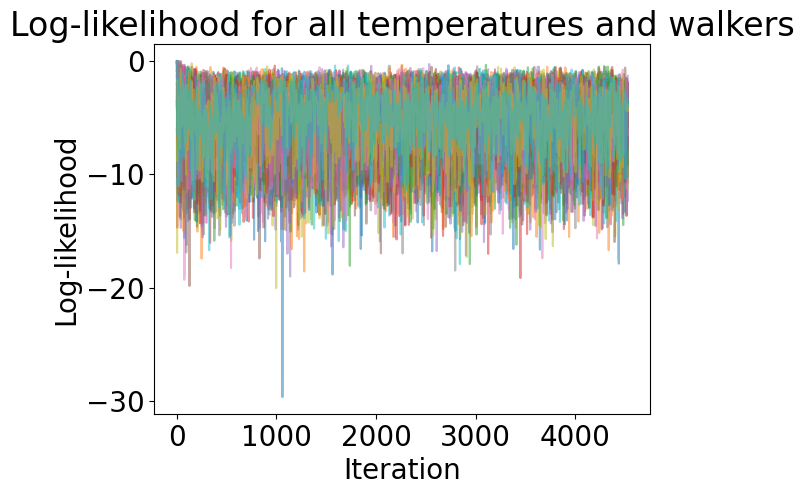

/home/people/sbarsanti/scratch/MCMC_scratch/


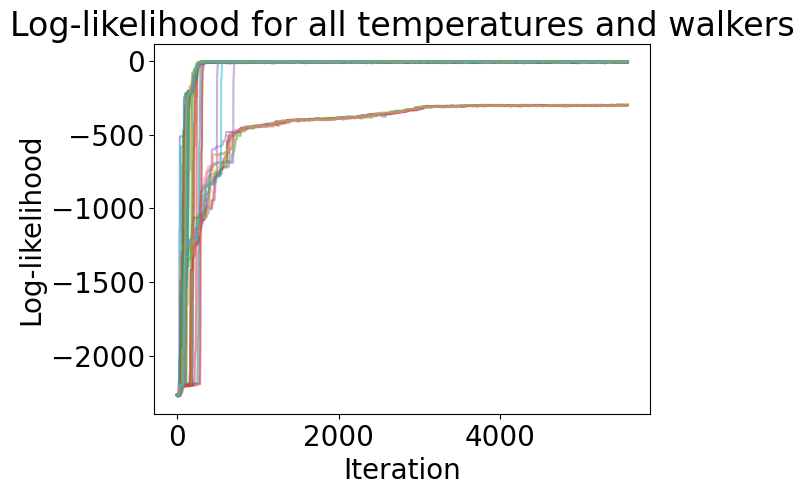

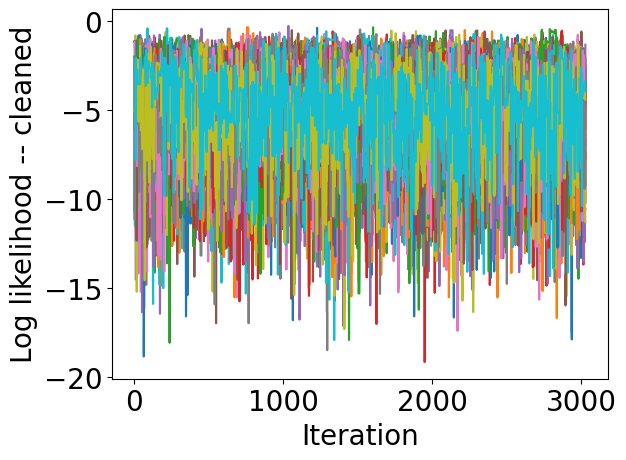

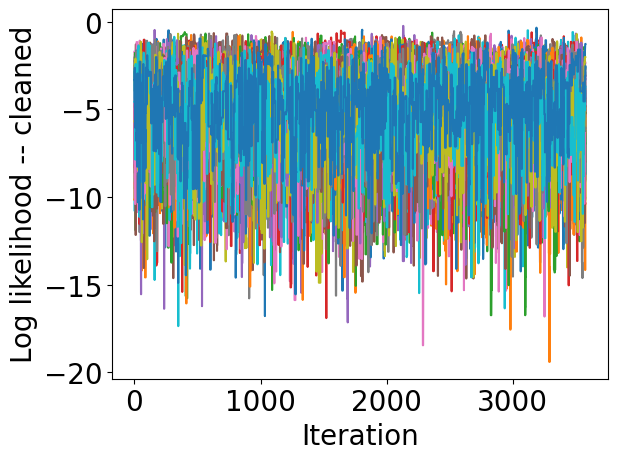

In [112]:
############ SPIN ###################################
#
file_path ="/home/people/sbarsanti/scratch/MCMC_scratch/"#
#
file_name_1PA ="MCMC_samps_1PAdSpinInj1PAdSpinRec_M100000.0_mu10.0_p024.381250923881847_Lambda0.0025000000000000005_SNR50_dist0.7040012731570409_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"
#F#67031#
#file_path ="/home/people/sbarsanti/scratch/MCMC_scratch/"#
#
file_name_0PA ="MCMC_samps_1PAdSpinInj0PAdSpinRec_M100000.0_mu10.0_p024.381250923881847_Lambda0.0025000000000000005_SNR50_dist0.7040012731570409_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"


samples_after_burnin_1PA, reader_1PA, log_like_1PA, N_params_1PA, N_temps_1PA = analyse_samples(file_path+file_name_1PA, discard= 0, plot_log_like = True, 
                                                                            trace_plot = False)
print(file_path)
samples_after_burnin_0PA, reader_0PA, log_like_0PA, N_params_0PA, N_temps_0PA = analyse_samples(file_path+file_name_0PA, discard= 0, plot_log_like = True, 
                                                                            trace_plot = False)

filtered_log_like_1PA, recast_samples_1PA= remove_bad_walkers(reader_1PA, log_like_threshold = -1000, burn =1500, plot_log_like = True)
filtered_log_like_0PA, recast_samples_0PA= remove_bad_walkers(reader_0PA, log_like_threshold = -200, burn =2000, plot_log_like = True)

file_path = "/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/data/"
save_samples_h5(recast_samples_1PA,
                no_samples = 20000000,
                #true_vals=[M, mu, p0, D, qS, phiS, qK, phiK, phi_phi0]
                ###1PAScalarVS0PAScalar###
                #true_vals=[1e6, 5e1,12.568936166598405,0.45762197821668216, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                #true_vals=[1e5, 1e1,24.381250923881847,0.17600102119878183, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                #true_vals=[1e5, 40,34.05694504889759,1.0039333937426218, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                ###1PAScalarVS1/0PAGR### 
                #true_vals=[1e5, 1e1,24.378402244813003,0.7041716088918832, 0.8, 2.2, 1.6, 1.2, 2.5,0.025**2],
                #true_vals=[1e5, 1e1,24.378402244813003,0.7041716088918832, 0.8, 2.2, 1.6, 1.2, 2.5],
                ###1PASpinScalar###
                true_vals=[1e5, 1e1,24.381250923881847,0.7040040847951273, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2,0.5],
                file_name="samples_1PAdSpinInj1PAdSpinRec_M100000.0_mu10.0_p024.381250923881847_Lambda0.0025000000000000005_SNR50_dist0.7040012731570409_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5",
                file_path=file_path)

save_samples_h5(recast_samples_0PA,
                no_samples = 200000,
                #true_vals=[M, mu, p0, D, qS, phiS, qK, phiK, phi_phi0]
                ###1PAScalarvs0PAScalar###
                #true_vals=[1e6, 5e1,12.568936166598405,0.45762197821668216, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                #true_vals=[1e5, 1e1,24.381250923881847,0.17600102119878183, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                #true_vals=[1e5, 40, 34.05694504889759,1.0039333937426218, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],
                ###1PAScalarVS1/0PAGR###
                #true_vals=[1e5, 1e1,24.378402244813003,0.7041716088918832, 0.8, 2.2, 1.6, 1.2, 2.5],
                ###1PASpinScalar###
                true_vals=[1e5, 1e1,24.381250923881847,0.7040040847951273, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2,0.5],
                file_name="samples_1PAdSpinInj0PAdSpinRec_M100000.0_mu10.0_p024.381250923881847_Lambda0.0025000000000000005_SNR50_dist0.7040012731570409_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5",
                file_path=file_path)

#file_path = "/home/people/sbarsanti/scratch/MCMC_scratch/"
file_path_charge_1pa = file_path + "samples_1PAdSpinInj1PAdSpinRec_M100000.0_mu10.0_p024.381250923881847_Lambda0.0025000000000000005_SNR50_dist0.7040012731570409_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"
file_path_charge_0pa = file_path + "samples_1PAdSpinInj0PAdSpinRec_M100000.0_mu10.0_p024.381250923881847_Lambda0.0025000000000000005_SNR50_dist0.7040012731570409_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"



#file_path_charge_1pa ="/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/data/samples_1PAdInj1PAdRec_M1000000.0_mu50.0_p012.568936166598405_Lambda0.0025000000000000005_SNR200_dist0.45762197821668216_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"
#file_path_charge_0pa ="/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/data/samples_1PAdInj0PAdRec_M1000000.0_mu50.0_p012.568936166598405_Lambda0.0025000000000000005_SNR200_dist0.45762197821668216_T1.0_pfin6.35_dt2.0_dstart0.1_Kerr.h5"
burned_samples_dict_EMRI_charge_1pa, param_labels_1pa, true_vals_EMRI_1pa =  load_samples_h5(file_path_charge_1pa)
burned_samples_dict_EMRI_charge_0pa, param_labels_0pa, true_vals_EMRI_0pa =  load_samples_h5(file_path_charge_0pa)

burned_samples_EMRI_charge_1pa = list(burned_samples_dict_EMRI_charge_1pa.values())
burned_samples_EMRI_charge_0pa = list(burned_samples_dict_EMRI_charge_0pa.values())



N_params= 11


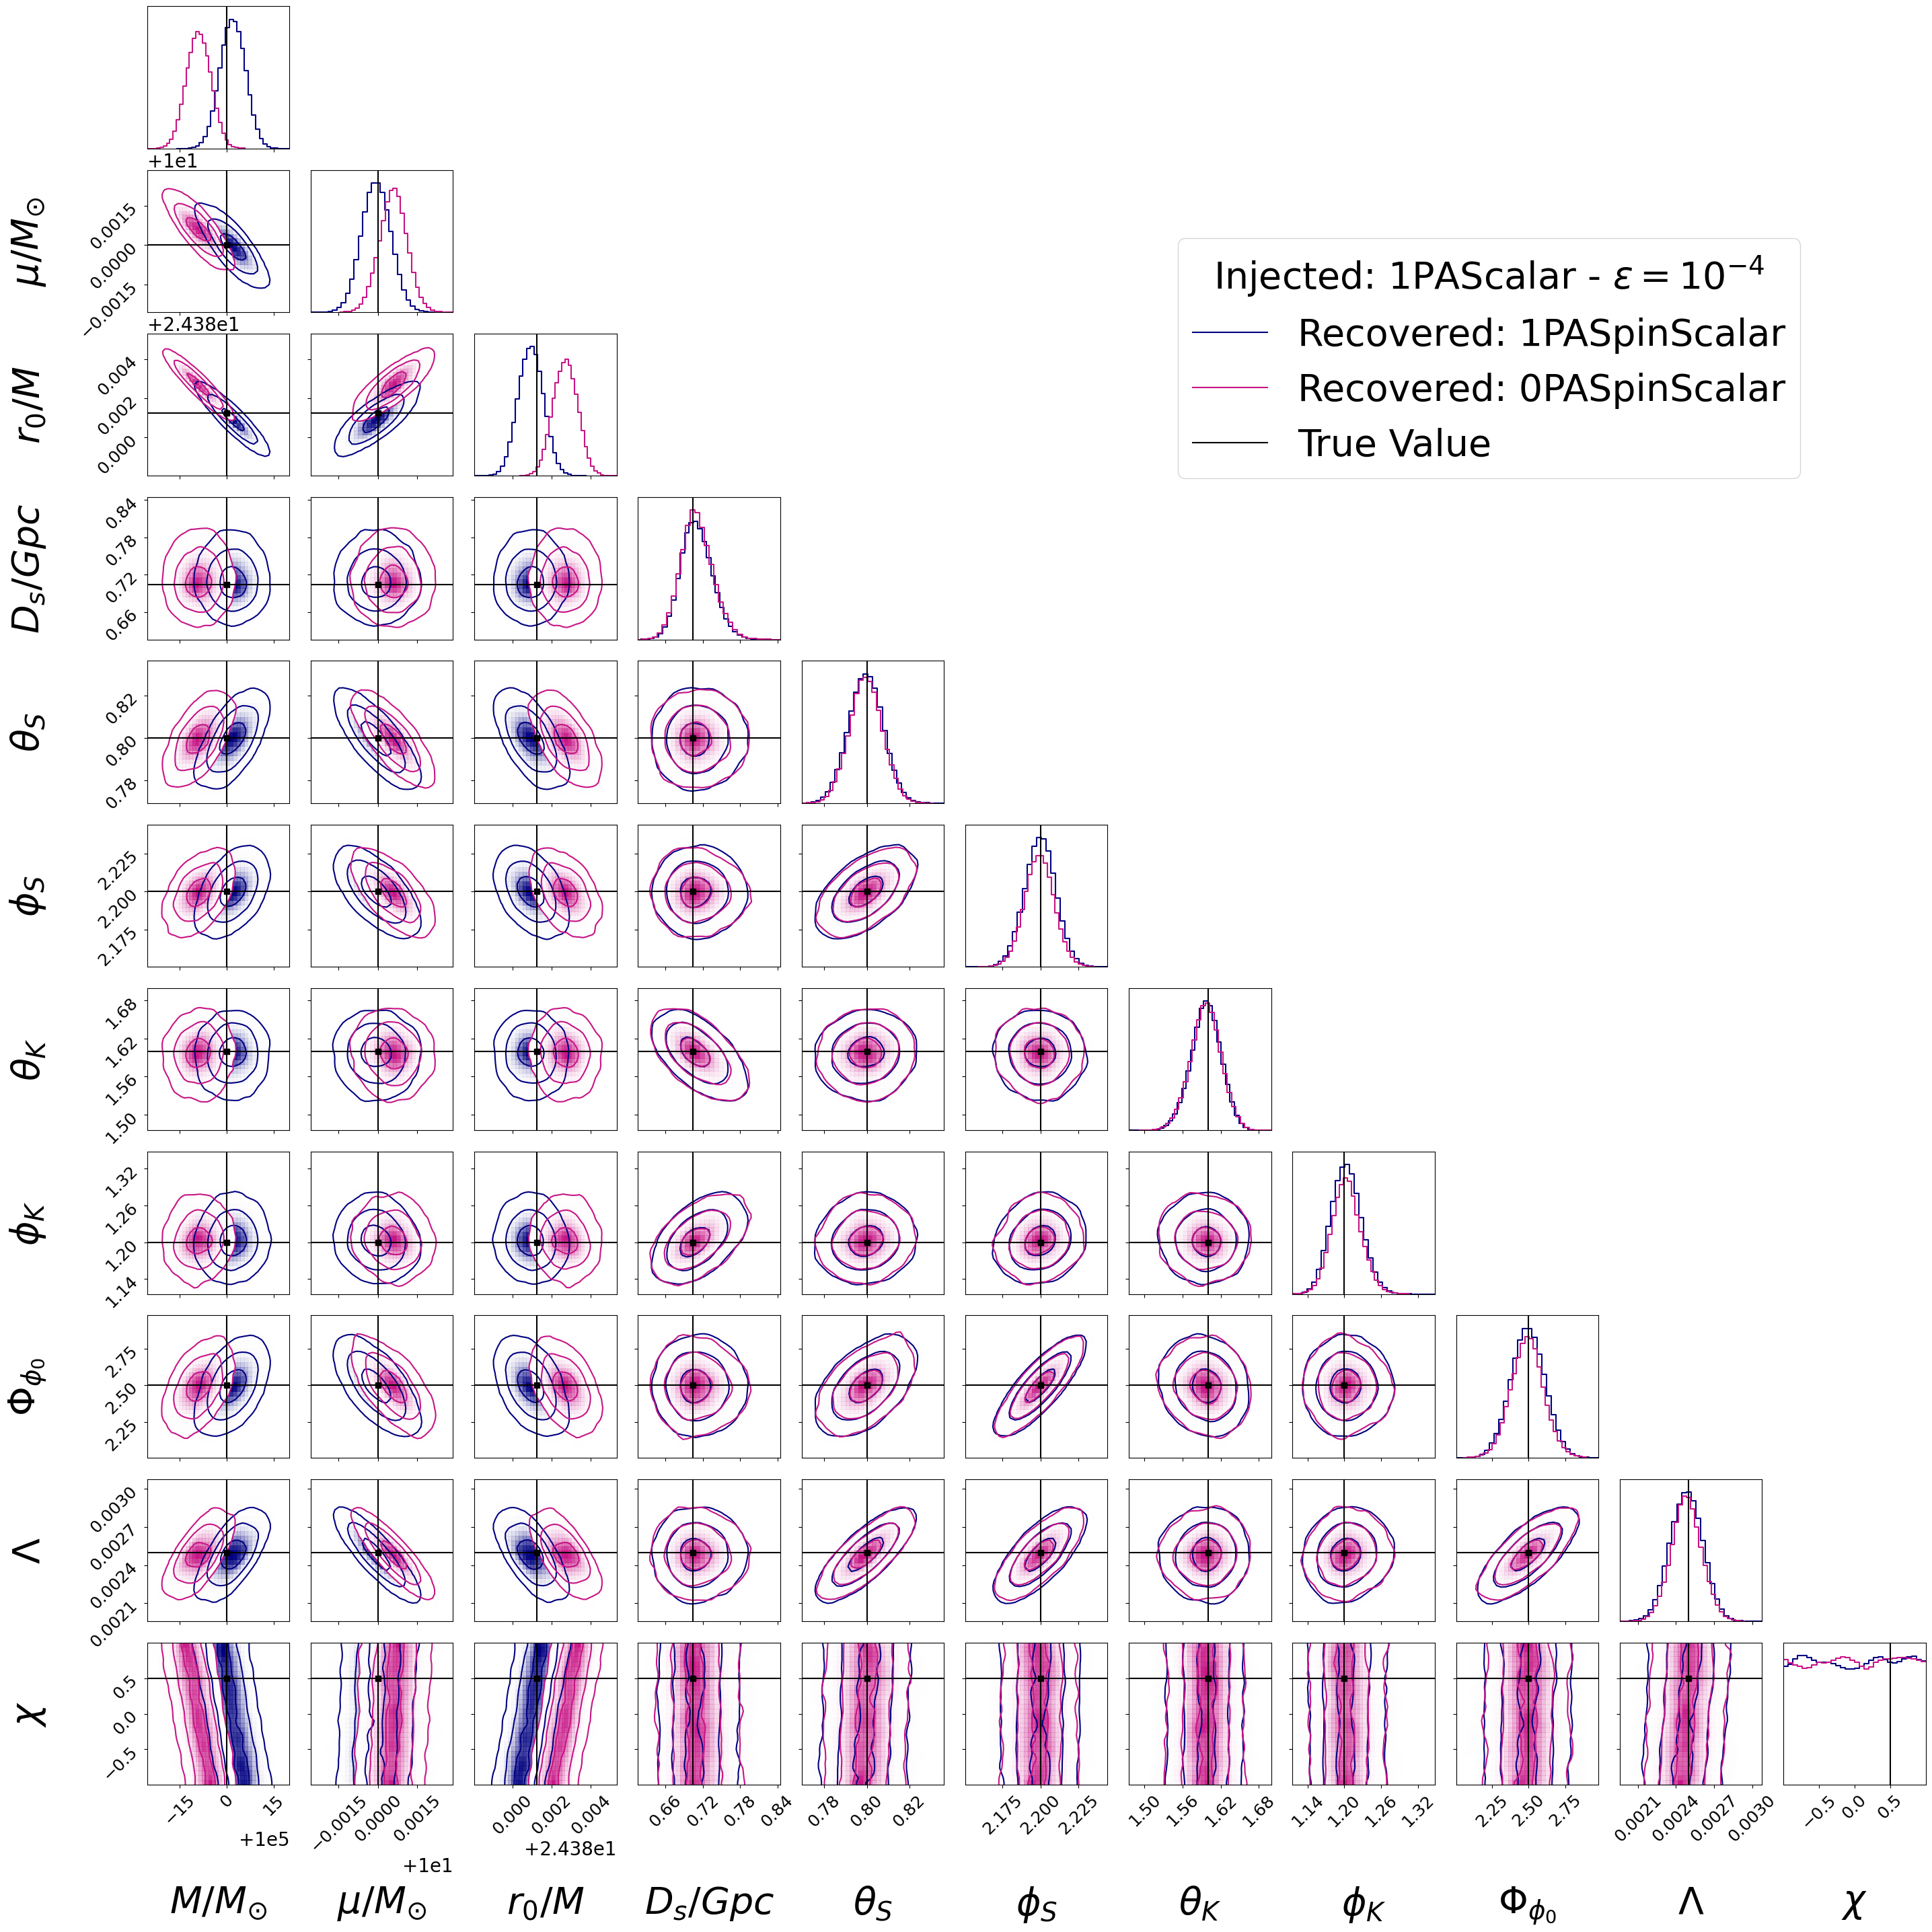

In [109]:
params_label_full = param_labels_1pa
N_params = len(param_labels_1pa)
corner_kwargs = dict(plot_datapoints=False,smooth1d=True,
                       labels=params_label_full, levels=(1 - np.exp(-0.5), 1 - np.exp(-2), 1 - np.exp(-9 / 2.)), 
                       label_kwargs=dict(fontsize=40), max_n_ticks=4,
                       show_titles=False, smooth = True, labelpad = 0.4)

samples_corner_charge_1pa = np.column_stack(burned_samples_EMRI_charge_1pa)
samples_corner_charge_0pa = np.column_stack(burned_samples_EMRI_charge_0pa)

#samples_corner_1eneg2 = np.column_stack(burned_samples_EMRI_1eneg2)

figure = corner.corner(samples_corner_charge_1pa,bins = 30, color = 'navy', **corner_kwargs)#crimson, indigo#navy
#figure = corner.corner(samples_corner_charge,bins = 30, color = 'blue', **corner_kwargs)
weights = (len(samples_corner_charge_1pa[:,0])/len(samples_corner_charge_0pa[:,0]))*np.ones(len(samples_corner_charge_0pa[:,0]))
corner.corner(samples_corner_charge_0pa,fig = figure,bins = 30, weights = weights, color = 'mediumvioletred', **corner_kwargs)#mediumvioletred#darkorange

axes = np.array(figure.axes).reshape((N_params, N_params))

for i in range(N_params):
    ax = axes[i, i]
    #if i == 7:
    #    mean = true_vals_EMRI_case_1[i]
    #    std = np.std(samples_corner_charge[:, i])
    #    ax.set_xlim(mean - 10*std, mean + 260*std)
    
    ax.axvline(true_vals_EMRI_1pa[i], color="k")

print("N_params=",N_params)
for yi in range(N_params):
    for xi in range(yi):
        ax = axes[yi, xi]
        #if xi == 7:
        #    mean_x = true_vals_EMRI_case_1[xi]
        #    std_x = np.std(samples_corner_charge[:, xi])
        #    ax.set_xlim(mean_x - 10*std_x, mean_x + 260*std_x)
           
        #if yi == 7:
        #     mean_y = true_vals_EMRI_case_1[yi]
         #    std_y = np.std(samples_corner_charge[:, yi])
         #    ax.set_ylim(mean_y - 10*std_y, mean_y + 260*std_y)
    
        ax.axhline(true_vals_EMRI_1pa[yi], color="k")
        ax.axvline(true_vals_EMRI_1pa[xi], color= "k")
        ax.plot(true_vals_EMRI_1pa[xi], true_vals_EMRI_1pa[yi], "sk")

for ax in figure.get_axes():
    ax.tick_params(axis='both', labelsize=18)

#red_line = mlines.Line2D([], [], color='darkblue', label=r'1PA - d=0.05 - $\chi=0.5$')
#blue_line = mlines.Line2D([], [], color='mediumvioletred', label=r'0PA - d=0.05 - $\chi=0.5$')
red_line = mlines.Line2D([], [], color='navy', label=r'Recovered: 1PASpinScalar')
blue_line = mlines.Line2D([], [], color='mediumvioletred', label=r'Recovered: 0PASpinScalar')
black_line = mlines.Line2D([], [], color='black', label='True Value')

plt.legend(handles=[red_line,blue_line,black_line], fontsize = 40, frameon = True, bbox_to_anchor=(0.25, N_params), loc="upper right", title = r"Injected: 1PAScalar - $\epsilon=10^{-4}$", title_fontproperties = FontProperties(size = 40))
plt.subplots_adjust(left=-0.1, bottom=-0.1, right=None, top=None, wspace=0.15, hspace=0.15)

#plt.savefig("/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/figures/corner_plot_mcmc_1PAdInjVS0PAdRec_M1e5_mu4e1_charge0.05_SNR100.pdf", bbox_inches='tight')


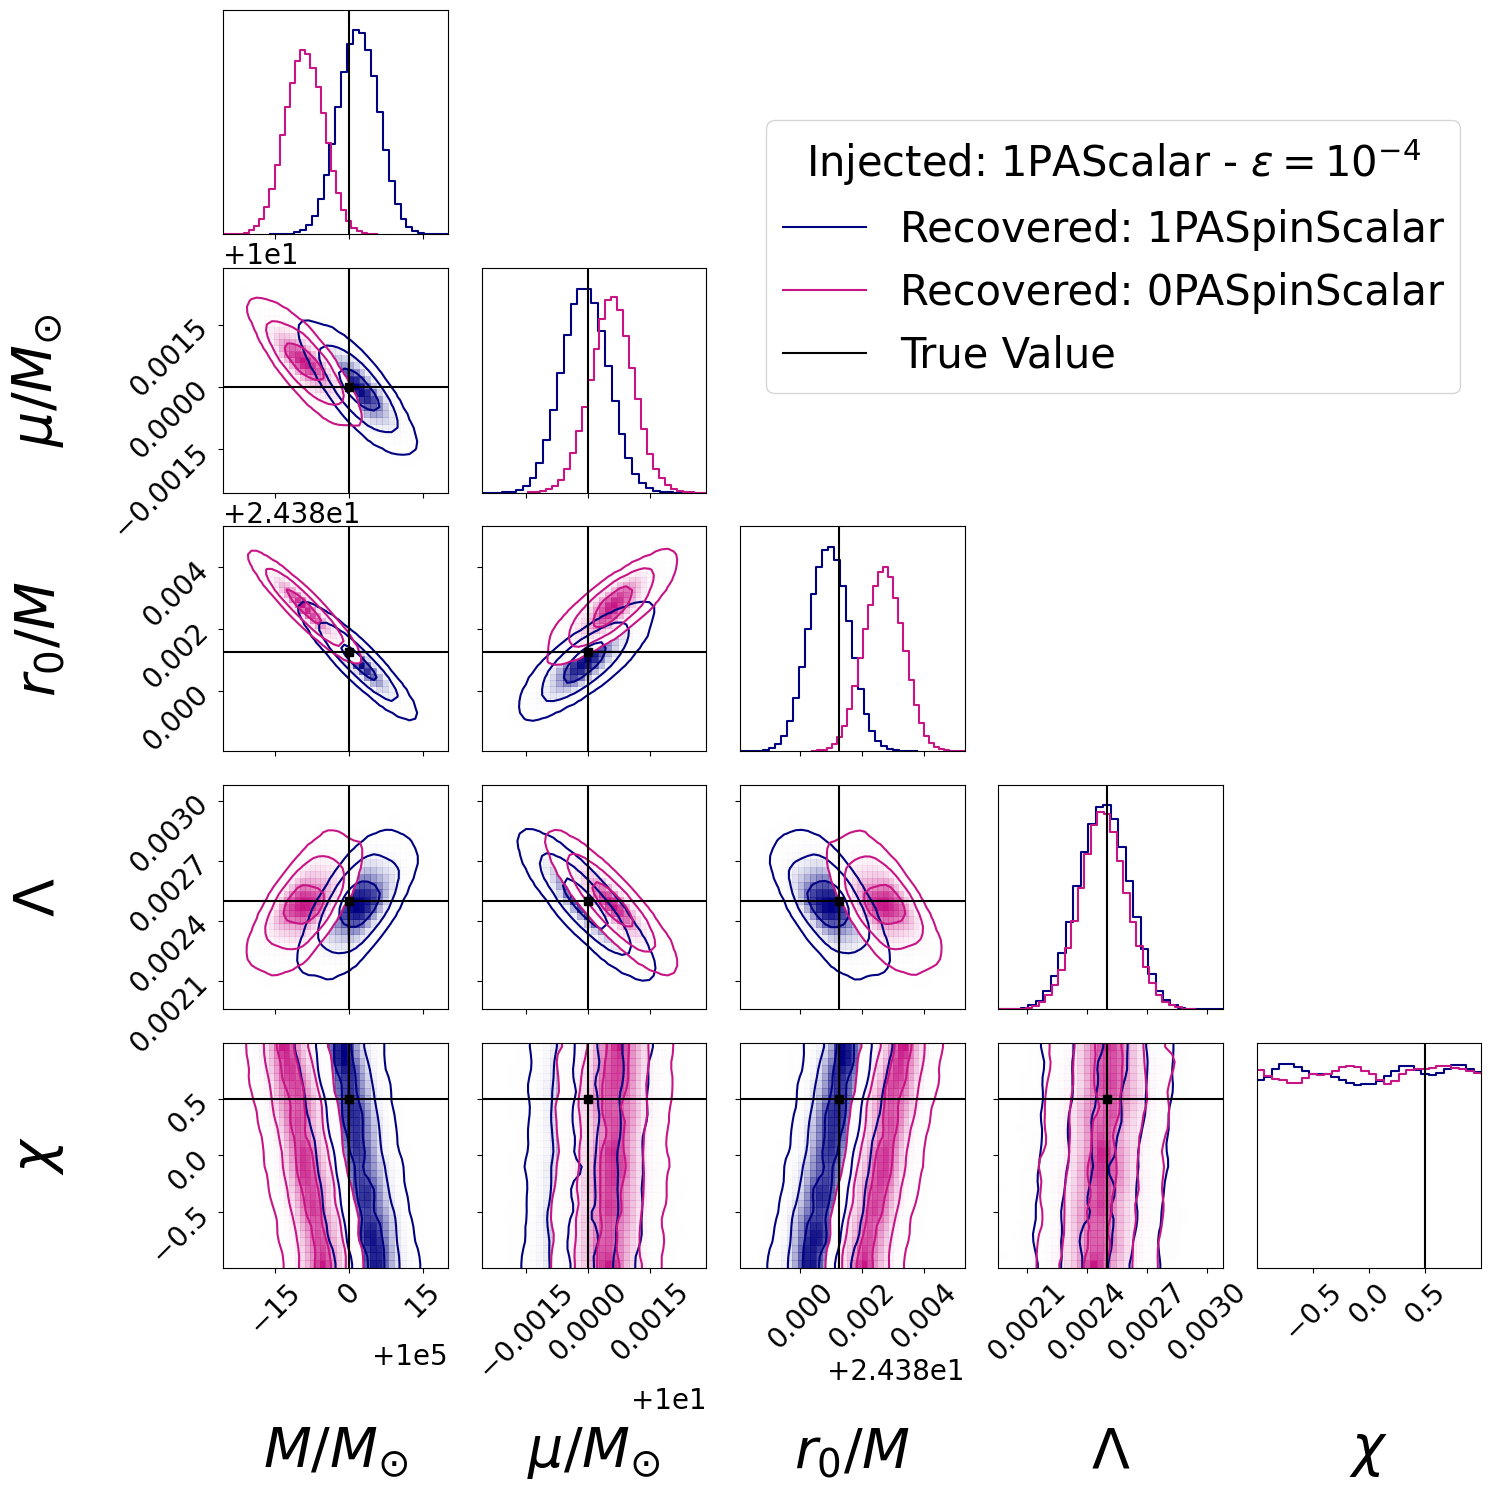

In [110]:
# === selezione parametri: primi 3 + ultimi 2 ===
idx_sel = [0, 1, 2, -2, -1]

params_label_sel = [params_label_full[i] for i in idx_sel]
true_vals_sel = true_vals_EMRI_1pa[idx_sel]

samples_corner_charge_1pa_sel = samples_corner_charge_1pa[:, idx_sel]
samples_corner_charge_0pa_sel = samples_corner_charge_0pa[:, idx_sel]

N_params_sel = len(idx_sel)

corner_kwargs_sel = dict(
    plot_datapoints=False,
    smooth1d=True,
    labels=params_label_sel,
    levels=(1 - np.exp(-0.5), 1 - np.exp(-2), 1 - np.exp(-9 / 2.)),
    label_kwargs=dict(fontsize=40),
    max_n_ticks=4,
    show_titles=False,
    smooth=True,
    labelpad=0.4
)

# === corner plot ===
figure = corner.corner(
    samples_corner_charge_1pa_sel,
    bins=30,
    color='navy',
    **corner_kwargs_sel
)

weights = (
    len(samples_corner_charge_1pa_sel[:, 0]) /
    len(samples_corner_charge_0pa_sel[:, 0])
) * np.ones(len(samples_corner_charge_0pa_sel[:, 0]))

corner.corner(
    samples_corner_charge_0pa_sel,
    fig=figure,
    bins=30,
    weights=weights,
    color='mediumvioletred',
    **corner_kwargs_sel
)

# === assi ===
axes = np.array(figure.axes).reshape((N_params_sel, N_params_sel))

# diagonale
for i in range(N_params_sel):
    ax = axes[i, i]
    ax.axvline(true_vals_sel[i], color="k")

# off-diagonale
for yi in range(N_params_sel):
    for xi in range(yi):
        ax = axes[yi, xi]
        ax.axhline(true_vals_sel[yi], color="k")
        ax.axvline(true_vals_sel[xi], color="k")
        ax.plot(true_vals_sel[xi], true_vals_sel[yi], "sk")

# tick size
for ax in figure.get_axes():
    ax.tick_params(axis='both', labelsize=20)

# legenda
red_line = mlines.Line2D([], [], color='navy', label=r'Recovered: 1PASpinScalar')
blue_line = mlines.Line2D([], [], color='mediumvioletred', label=r'Recovered: 0PASpinScalar')
black_line = mlines.Line2D([], [], color='black', label='True Value')

plt.legend(
    handles=[red_line, blue_line, black_line],
    fontsize=30,
    frameon=True,
    bbox_to_anchor=(1., 5.2),
    loc="upper right",
    title=r"Injected: 1PAScalar - $\epsilon=  10^{-4}$",
    title_fontproperties=FontProperties(size=30)
)

plt.subplots_adjust(left=-0.1, bottom=-0.1, wspace=0.15, hspace=0.15)
#plt.savefig("/home/people/sbarsanti/scratch/MCMC_scratch/Hybrid1PAScalarVS0PAScalarResults/M50000mu10SNR200/corner_subset_1PAdInjVS0PAdRec_M5e4_mu1e1_charge0.05_SNR200.pdf", bbox_inches='tight')
#plt.savefig("/home/people/sbarsanti/scratch/MCMC_scratch/EMRI-1PA-Scalar/figures/corner_subset_1PAdInjVS0PAdRec_M1e5_mu4e1_charge0.05_SNR100.pdf", bbox_inches='tight')


In [113]:
# Estrai campioni dal cold chain (temperatura 0)
samples_flat = recast_samples_0PA[0]   # shape = (N_iter*N_walkers, N_params)
print("length samples flat = ", len(samples_flat))
# Estrai loglike flatten foro T=0
loglike_flat = filtered_log_like_0PA[:, 0, :].reshape(-1)

# taglia se lunghezze non combaciano
min_len = min(len(samples_flat), len(loglike_flat))

samples_flat = samples_flat[:min_len]
loglike_flat = loglike_flat[:min_len]

# Trova il massimo
imax = np.nanargmax(loglike_flat)
best_params = samples_flat[imax]
best_loglike = loglike_flat[imax]

print("Best fit params =", best_params)
print("Best log-likelihood =", best_loglike)

loglike_initial_allwalkers = log_like_0PA[0, 0, :]
loglike_initial_mean = np.nanmean(log_like_0PA[0, 0, :])
print("loglike_initial_allwalkers=",loglike_initial_allwalkers)
print("loglike_initial_mean=",loglike_initial_mean)

idx = np.nanargmax(log_like_0PA[0,0,:])
loglike_initial_best = log_like_0PA[0,0,idx]
params_initial_best = reader_0PA.get_chain()['model_0'][0,0,idx,0,:]
print("loglike_initial_best=",loglike_initial_best)

tau = reader_0PA.get_autocorr_time()
print("tau=", tau)


length samples flat =  146698
Best fit params = [ 9.99928672e+04  1.00005058e+01  2.43824071e+01  7.01360494e-01
  8.00459609e-01  2.19932040e+00  1.60055564e+00  1.19699688e+00
  2.47491212e+00  2.47379224e-03 -3.85729108e-01]
Best log-likelihood = -0.24109876405375844
loglike_initial_allwalkers= [-2267.26405996 -2267.4244436  -2269.1315081  -2266.81693171
 -2267.46833722 -2268.50535731 -2267.85734562 -2266.39125744
 -2267.29797109 -2265.26525785 -2268.9377456  -2268.31731204
 -2269.02454139 -2264.49329588 -2265.1328862  -2269.57517694
 -2266.56581611 -2267.8033356  -2269.51397431 -2266.26195837
 -2267.25063608 -2267.60988589 -2267.004066   -2269.22081205
 -2268.98735138 -2264.68804066 -2268.01036749 -2265.26751801
 -2266.55865131 -2268.67373254 -2266.77139792 -2268.89247943
 -2268.06720622 -2268.79396681 -2268.4595853  -2267.45069131
 -2267.26568332 -2265.65928166 -2268.1441832  -2269.14918215
 -2267.54890944 -2267.18033233 -2267.78666539 -2265.61035432
 -2267.89794505 -2266.85428371

In [114]:
# =============================
# COMPUTING BIASES 
# =============================

# =============================
# 1) IMPORTING TRUE VALUES
# =============================
theta_true = true_vals_EMRI_1pa 

samples_flat_0pa = recast_samples_0PA[0]
samples_flat_1pa = recast_samples_1PA[0] #samples_corner_charge #

# =============================
# 2) POSTERIOR STATISTICS 
# =============================
posterior_mean_1pa   = np.mean(samples_flat_1pa, axis=0)
posterior_std_1pa    = np.std(samples_flat_1pa, axis=0, ddof=1)
posterior_mean_0pa   = np.mean(samples_flat_0pa, axis=0)
posterior_std_0pa    = np.std(samples_flat_0pa, axis=0, ddof=1)

# =============================
# 3) PRINTING RESULTS
# =============================
bias_0pa = posterior_mean_0pa - theta_true
z_0pa = bias_0pa / posterior_std_0pa   # <-- sigma dal modello A

for i in range(len(theta_true)):
    print(f"\n=== PARAMETRO {i} ===")
    print("true =", theta_true[i])
    print("mean(A) =", posterior_mean_1pa[i], " sigma(A) =", posterior_std_1pa[i])
    print("mean(B) =", posterior_mean_0pa[i])

    print("bias(B) =", bias_0pa[i], f" (z = {z_0pa[i]:.3f})")
    print(f"--> Il bias del modello B è {abs(z_0pa[i]):.3f} volte sigma(A)")


=== PARAMETRO 0 ===
true = 100000.0
mean(A) = 100001.94942868501  sigma(A) = 3.849599731602214
mean(B) = 99990.96945064627
bias(B) = -9.030549353730748  (z = -2.399)
--> Il bias del modello B è 2.399 volte sigma(A)

=== PARAMETRO 1 ===
true = 10.0
mean(A) = 9.99993992187556  sigma(A) = 0.0005315017918486808
mean(B) = 10.000598566954137
bias(B) = 0.0005985669541370697  (z = 1.179)
--> Il bias del modello B è 1.179 volte sigma(A)

=== PARAMETRO 2 ===
true = 24.381250923881847
mean(A) = 24.38093319651512  sigma(A) = 0.0006145917308934991
mean(B) = 24.38271676155396
bias(B) = 0.0014658376721143895  (z = 2.437)
--> Il bias del modello B è 2.437 volte sigma(A)

=== PARAMETRO 3 ===
true = 0.7040040847951273
mean(A) = 0.7105983794846523  sigma(A) = 0.024157238598723593
mean(B) = 0.7109281071756414
bias(B) = 0.006924022380514039  (z = 0.277)
--> Il bias del modello B è 0.277 volte sigma(A)

=== PARAMETRO 4 ===
true = 0.8
mean(A) = 0.7994882462120506  sigma(A) = 0.007717027554097385
mean(B) = 0

## 0PAScalar VS -1PNScalar

In [ ]:
# Now analyse the results using 9PN for circular orbits

def analyse_samples(file_path, discard = 0, plot_log_like = True, trace_plot = False):
    reader = eryn_HDF_Backend(file_path,read_only = True)

    N_iterations = reader.get_chain()['model_0'].shape[0]
    N_temps = reader.get_chain()['model_0'].shape[1]
    N_walkers = reader.get_chain()['model_0'].shape[2]
    N_params = reader.get_chain()['model_0'].shape[-1]

    samples_after_burnin = [reader.get_chain(discard = discard)['model_0'][:,i].reshape(-1,N_params) 
                        for i in range(N_temps)]  # Take true chain]

    log_like = reader.get_log_like(discard = discard)
    #log_like = log_like[:-2000]

    '''
    MOSTRA SOLO NTEMP=1 !!
    if plot_log_like:
        plt.plot(log_like[:,0,:]); 
        plt.xlabel(r'Iteration')
        plt.ylabel(r'Log likelihood')
        plt.savefig('loglike_plot_1PAinj0PArec.png', bbox_inches='tight')
        plt.show()
    '''

    for t in range(N_temps):
        for w in range(N_walkers):
            plt.plot(log_like[:, t, w], alpha=0.5, label=f'T{t}-W{w}' if N_temps <= 2 else None)

    plt.xlabel('Iteration')
    plt.ylabel('Log-likelihood')
    plt.title('Log-likelihood for all temperatures and walkers')
    #plt.savefig('loglike_plot_alltemps.png', bbox_inches='tight')
    plt.show()
        

    param_labels = [r"$M/M_{\odot}$", r"$\mu/M_{\odot}$", 
                         r"$r_{0}/M$", r"$D_{s}/Gpc$", 
                         r"$\theta_{S}$", r"$\phi_{S}$", r"$\theta_{K}$", r"$\phi_{K}$", 
                         r"$\Phi_{\phi_{0}}$",r"$\Lambda$"]
    
    if trace_plot == True:
        print("here1")
        fig, axs = plt.subplots(N_params, figsize=(12, 2.5 * N_params), sharex=True)
        if N_params == 1:
            print("here2")
            axs = [axs]
        for i in range(N_params):
            print("here3")
            for w in range(N_walkers):
                axs[i].plot(reader.get_chain()['model_0'][:, 0, w, 0, i], alpha=0.5, lw=0.5)
            axs[i].set_ylabel(param_labels[i] if param_labels else f'param {i}')
            #if true_vals is not None:
            #    axs[i].axhline(true_vals[i], color='r', linestyle='--', label='True value')
            #    axs[i].legend(loc='upper right', fontsize=6)
        axs[-1].set_xlabel("Iteration")
        plt.suptitle("Parameter Trace Plot")
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        print("here5")
        #plt.savefig('trace_plot_1PAdinj1PAGRrec.png', bbox_inches='tight')
        plt.show()  

    
        
    return samples_after_burnin, reader, log_like, N_params, N_temps 

def corner_plot(burned_samples, true_params, param_labels, corner_kwargs, title = r'Corner plot', plot_name = None):
    N_params = len(param_labels)
    true_params = true_params[0:N_params]
    trunc_samples = burned_samples[0][:,:N_params]
    print(trunc_samples.shape)
    
    samples_corner = np.column_stack(trunc_samples)

    figure = corner.corner(trunc_samples,bins = 30, color = 'blue', **corner_kwargs)

    
    axes = np.array(figure.axes).reshape((N_params, N_params))

    for i in range(N_params):
        ax = axes[i, i]
        ax.axvline(true_params[i], color="k")

    for yi in range(N_params):
        for xi in range(yi):
            ax = axes[yi, xi]
            ax.axhline(true_params[yi], color="k")
            ax.axvline(true_params[xi],color= "k")
            ax.plot(true_params[xi], true_params[yi], "sk")

    for ax in figure.get_axes():
        ax.tick_params(axis='both', labelsize=18)

    blue_line = mlines.Line2D([], [], color='blue', label=r'Posterior Distributions')
    black_line = mlines.Line2D([], [], color='black', label='True Value')

    # plt.legend(handles=[blue_line,black_line], fontsize = 65, frameon = True, bbox_to_anchor=(0.25, N_params), loc="upper right", title = title, title_fontproperties = FontProperties(size = , weight = 'bold'))
    # plt.subplots_adjust(left=-0.1, bottom=-0.1, right=None, top=None, wspace=0.15, hspace=0.15)
    if plot_name:
        plt.savefig(plot_name, bbox_inches = "tight")
    return figure

def remove_bad_walkers(reader_from_sampler, log_like_threshold = -170, burn = 400, plot_log_like = True):
 
    N_temps = reader_from_sampler.get_chain()['model_0'].shape[1]
    N_params = reader_from_sampler.get_chain()['model_0'].shape[-1]
    samples = reader_from_sampler.get_chain(discard = burn)['model_0']
    log_like = reader_from_sampler.get_log_like(discard = burn)
    
    # Define the log-likelihood threshold
    #log_like_threshold = -170
    
    # Identify walkers that ever go below the threshold
    bad_walkers = np.any(log_like < log_like_threshold, axis=0)  # Shape: (1, 50)
    
    # Convert to boolean mask (negate to keep good walkers)
    good_walkers_mask = ~bad_walkers.squeeze()  # Shape: (50,)
    
    filtered_log_like = log_like[:, :, good_walkers_mask]  # New shape: (1208, 1, <fewer walkers>)
    filtered_samples = samples[:, :, good_walkers_mask, :, :]  # New shape: (1208, 1, <fewer walkers>, 1, 12)

    recast_samples = [filtered_samples[:,i].reshape(-1,N_params) for i in range(N_temps)]  # Take true chain]  

    if plot_log_like:
        plt.plot(filtered_log_like[:,0,:]);
        plt.xlabel(r'Iteration')
        plt.ylabel(r'Log likelihood -- cleaned')
        plt.savefig('loglike_plot_cleaned_1PAinj0PArec.png', bbox_inches='tight')
        plt.show()

    param_labels = [r"$M/M_{\odot}$", r"$\mu/M_{\odot}$", 
                         r"$r_{0}/M$", r"$D_{s}/Gpc$", 
                         r"$\theta_{S}$", r"$\phi_{S}$", r"$\theta_{K}$", r"$\phi_{K}$", 
                         r"$\Phi_{\phi_{0}}$",r"$\Lambda$",r"$\chi$"]

    if plot_log_like == False:
        fig, axs = plt.subplots(N_params, figsize=(12, 2.5 * N_params), sharex=True)
        if N_params == 1:
            axs = [axs]
        n_good_walkers = filtered_samples.shape[2]
        for i in range(N_params):
            for w in range(n_good_walkers):
                axs[i].plot(samples[:, 0, w, 0, i], alpha=0.5, lw=0.5)
            axs[i].set_ylabel(param_labels[i] if param_labels else f'param {i}')
            #if true_vals is not None:
            #    axs[i].axhline(true_vals[i], color='r', linestyle='--', label='True value')
            #    axs[i].legend(loc='upper right', fontsize=6)
        axs[-1].set_xlabel("Iteration")
        plt.suptitle("Parameter Trace Plot -- cleaned")
        plt.tight_layout()
        plt.subplots_adjust(top=0.95)
        plt.savefig(f'trace_plot_1PAdinj1PAGRrec_burn{burn}.png', bbox_inches='tight')
        plt.show()       
    
    return filtered_log_like, recast_samples


import h5py

def save_samples_h5(samples, no_samples=400000000, 
                    true_vals = None, 
                    file_name = "samples.h5", param_labels="param_labels",
                    file_path = None):
    samples_array = samples[0]
    
    # Truncate to last 30,000 samples
    truncated_samples = samples_array[-1*no_samples:, :]
    
    # Parameter labels and true values
    params_label_full = [r"$M/M_{\odot}$", r"$\mu/M_{\odot}$", 
                         r"$r_{0}/M$", r"$D_{s}/Gpc$", 
                         r"$\theta_{S}$", r"$\phi_{S}$", r"$\theta_{K}$", r"$\phi_{K}$", 
                         r"$\Phi_{\phi_{0}}$",r"$\Lambda$"]#,r"$\chi$"]
    
    #true_vals_EMRI_case_1 = [1e6, 10.0, 0.998, 7.7275, 0.73, 2.204, 0.8, 2.2, 1.6, 1.2, 2.0, 3.0]
    
    # Create dictionary for samples
    samples_dict = {
        label: truncated_samples[:, i] for i, label in enumerate(params_label_full)
    }
    
    # Save to .h5 file
    with h5py.File(file_path + file_name, "w") as f:
        # Save each parameter's samples
        for key, values in samples_dict.items():
            f.create_dataset(f"samples/{key}", data=values)
        
        # Save true values
        f.create_dataset("true_values", data=true_vals)
        
        # Save parameter labels (as fixed-length ASCII strings)
        dt = h5py.string_dtype(encoding='utf-8')
        f.create_dataset(param_labels, data=np.array(params_label_full, dtype=dt))


def load_samples_h5(file_path):
    with h5py.File(file_path, "r") as f:
        # Load parameter labels
        param_labels = [label.decode('utf-8') if isinstance(label, bytes) else label
                        for label in f["param_labels"][()]]

        # Load true values
        true_vals = f["true_values"][()]

        # Load samples into a dictionary
        samples_dict = {}
        for label in param_labels:
            samples_dict[label] = f[f"samples/{label}"][()]

    return samples_dict, param_labels, true_vals

In [ ]:
file_path="/home/people/sbarsanti/scratch/MCMC_scratch/final/"

file_name="MCMC_samps_0PAdInjPNRec_PNstudy_M100000.0_mu10_p024.381250923886657_Lambda0.0025000000000000005_SNR50_dist0.7053452441164779_T1.0_priorA-0.0_0.3_pfin0PAScalar6.362605981942898_dt2.0_dstart0.1_ntemps1_walkers50_Kerr.h5"
file_name="MCMC_samps_0PAdInj0PARec_PNstudy_M100000.0_mu10_p024.381250923886657_Lambda0.0025000000000000005_SNR50_dist0.7053452441164779_T1.0_priorA-0.0_0.3_pfin0PAScalar6.362605981942898_dt2.0_dstart0.1_ntemps1_walkers50_Kerr.h5"


samples_after_burnin, reader, log_like, N_params, N_temps = analyse_samples(file_path+file_name, discard= 0, plot_log_like = True, 
                                                                            trace_plot = False)
print("Ntemps=", N_temps)
#print("samples=", samples_after_burnin
filtered_log_like, recast_samples_pn = remove_bad_walkers(reader, log_like_threshold = -50, burn =2300, plot_log_like = True)

save_samples_h5(recast_samples_pn,
                #samples_after_burnin,
                #[samples_array_clean],
                no_samples = 20000000000,
                #true_vals=[M, mu, p0, D, qS, phiS, qK, phiK, phi_phi0]
                #true_vals=[1e6, 5e1, 12.6, 0.7597644397073258, 0.8, 2.2, 1.6, 1.2, 2.0, 0.04],  # Inserisci i tuoi 9 true values
                true_vals=[1e5, 1e1,24.381250923886657,0.7040040847951273, 0.8, 2.2, 1.6, 1.2, 2.5,0.05**2],#,0.025**2],#,0.05**2],#,,0.05**2],#,0.5],#,0.05**2,0.5],#,0.025**2],#,0.05**2],#,0.5],
                file_name="samples_pn.h5",
                file_path=file_path)

#M = 1e6; mu = 5e1; a = 0.; p0 = 12.6; e0 = 0.; x_I0 = 1.0
#SNR_choice = 200;
#qS = 0.8 ; phiS = 2.2; qK = 1.6; phiK = 1.2;
#Phi_phi0 = 2.0; Phi_theta0 = 0.0; Phi_r0 = 0.0

file_path_charge = file_path + "samples_pn.h5"
file_path_charge_0pa = file_path + "samples_0pa.h5"

burned_samples_dict_EMRI_charge, param_labels, true_vals_EMRI =  load_samples_h5(file_path_charge)
burned_samples_dict_EMRI_charge_0pa, param_labels, true_vals_EMRI =  load_samples_h5(file_path_charge_0pa)
#burned_samples_dict_EMRI_charge_1pa, param_labels_1pa, true_vals_EMRI_case_1 =  load_samples_h5(file_path_charge_1pa)

burned_samples_EMRI_charge = list(burned_samples_dict_EMRI_charge.values())
#burned_samples_EMRI_charge_1pa = list(burned_samples_dict_EMRI_charge_1pa.values())
burned_samples_EMRI_charge_0pa = list(burned_samples_dict_EMRI_charge_0pa.values())
#print("burned_samples_EMRI_1eneg5 =", burned_samples_EMRI_1eneg5)

N_params= 10


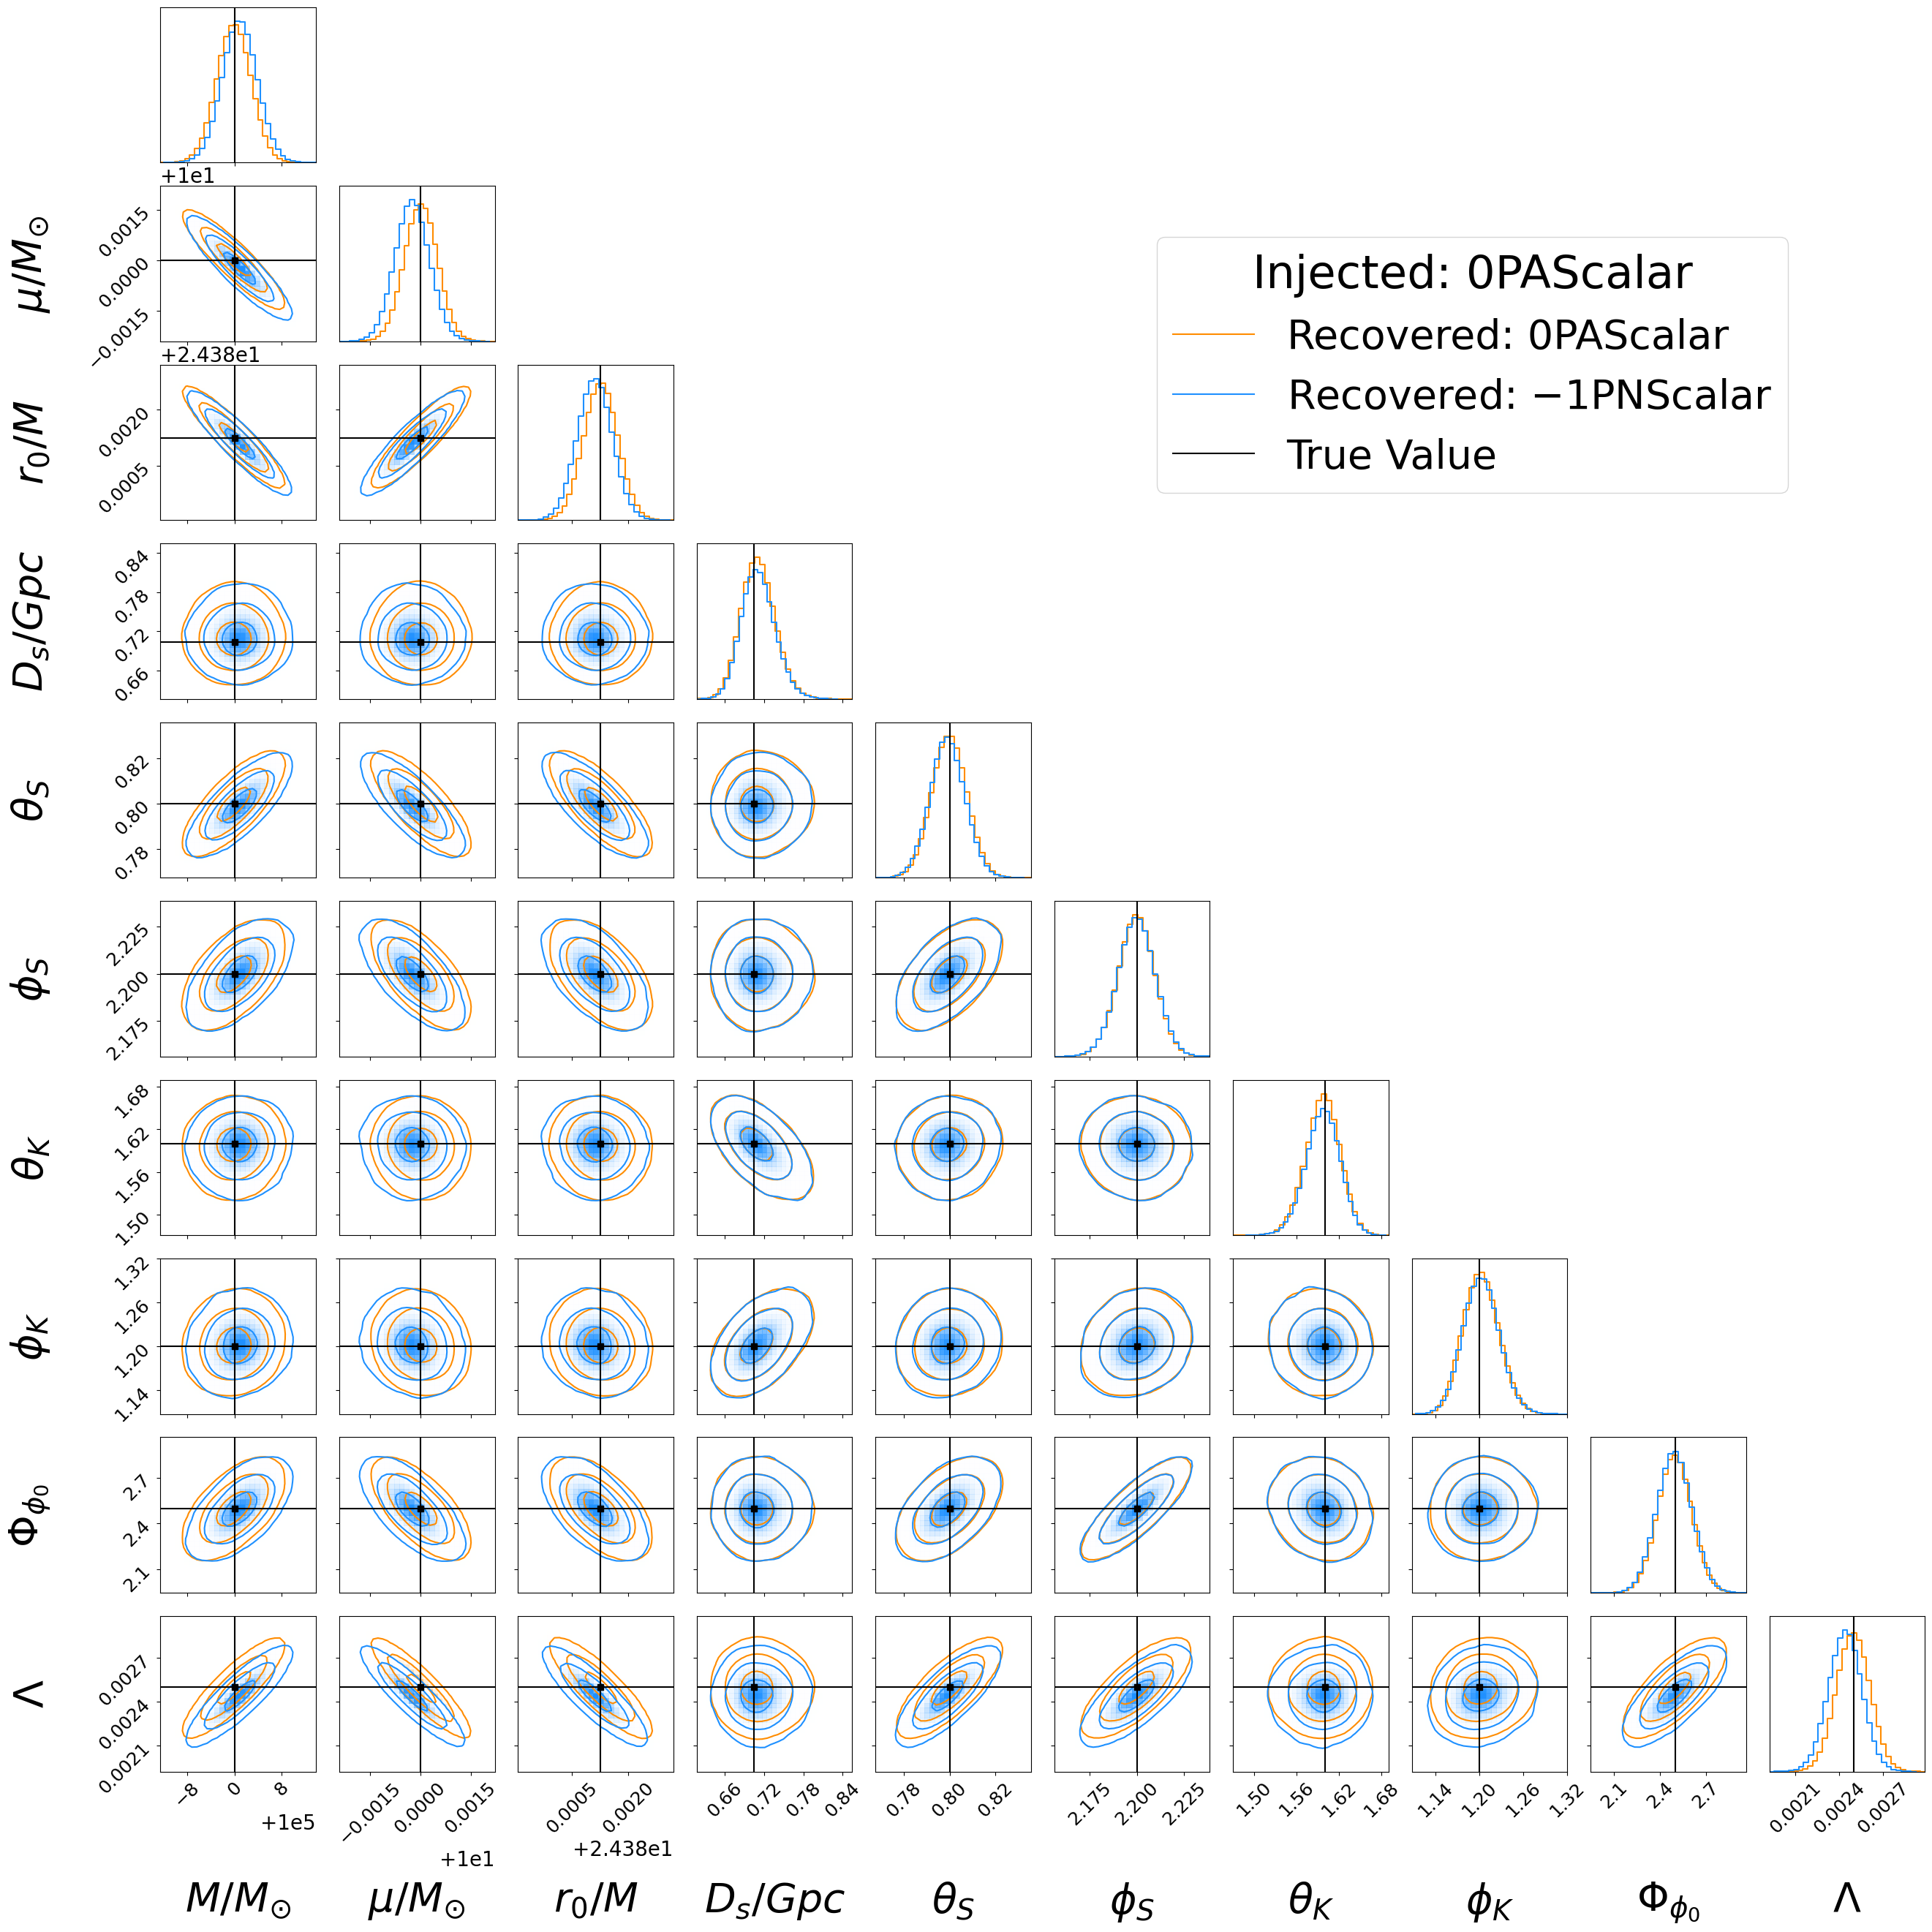

In [ ]:
params_label_full = param_labels
N_params = len(param_labels)
corner_kwargs = dict(plot_datapoints=False,smooth1d=True,
                       labels=params_label_full, levels=(1 - np.exp(-0.5), 1 - np.exp(-2), 1 - np.exp(-9 / 2.)), 
                       label_kwargs=dict(fontsize=40), max_n_ticks=4,
                       show_titles=False, smooth = True, labelpad = 0.4)

samples_corner_charge = np.column_stack(burned_samples_EMRI_charge)
samples_corner_charge_0pa = np.column_stack(burned_samples_EMRI_charge_0pa)
#samples_corner_charge_1pa = np.column_stack(burned_samples_EMRI_charge_1pa)
#print("samples_corner_1eneg5=",samples_corner_1eneg5)
#print("Varianze delle colonne:", np.var(samples_corner_1eneg5, axis=0))
#print("Shape:", samples_corner_charge.shape)

#samples_corner_1eneg2 = np.column_stack(burned_samples_EMRI_1eneg2)

figure = corner.corner(samples_corner_charge_0pa,bins = 30, color = 'darkorange', **corner_kwargs)#crimson, indigo#navy
#figure = corner.corner(samples_corner_charge,bins = 30, color = 'blue', **corner_kwargs)
weights = (len(samples_corner_charge_0pa[:,0])/len(samples_corner_charge[:,0]))*np.ones(len(samples_corner_charge[:,0]))
corner.corner(samples_corner_charge,fig = figure,bins = 30, weights = weights, color = 'dodgerblue', **corner_kwargs)#mediumvioletred#darkorange
#weights = (len(samples_corner_charge_1pa[:,0])/len(samples_corner_charge_0pa[:,0]))*np.ones(len(samples_corner_charge_0pa[:,0]))
#corner.corner(samples_corner_charge_0pa,fig = figure,bins = 30, weights = weights, color = 'darkorange', **corner_kwargs)


axes = np.array(figure.axes).reshape((N_params, N_params))

for i in range(N_params):
    ax = axes[i, i]
    #if i == 7:
    #    mean = true_vals_EMRI_case_1[i]
    #    std = np.std(samples_corner_charge[:, i])
    #    ax.set_xlim(mean - 10*std, mean + 260*std)
    
    ax.axvline(true_vals_EMRI[i], color="k")

print("N_params=",N_params)
for yi in range(N_params):
    for xi in range(yi):
        ax = axes[yi, xi]
        #if xi == 7:
        #    mean_x = true_vals_EMRI_case_1[xi]
        #    std_x = np.std(samples_corner_charge[:, xi])
        #    ax.set_xlim(mean_x - 10*std_x, mean_x + 260*std_x)
           
        #if yi == 7:
        #     mean_y = true_vals_EMRI_case_1[yi]
         #    std_y = np.std(samples_corner_charge[:, yi])
         #    ax.set_ylim(mean_y - 10*std_y, mean_y + 260*std_y)
    
        ax.axhline(true_vals_EMRI[yi], color="k")
        ax.axvline(true_vals_EMRI[xi], color= "k")
        ax.plot(true_vals_EMRI[xi], true_vals_EMRI[yi], "sk")

for ax in figure.get_axes():
    ax.tick_params(axis='both', labelsize=18)

#red_line = mlines.Line2D([], [], color='darkblue', label=r'1PA - d=0.05 - $\chi=0.5$')
#blue_line = mlines.Line2D([], [], color='mediumvioletred', label=r'0PA - d=0.05 - $\chi=0.5$')
red_line = mlines.Line2D([], [], color='darkorange', label=r'Recovered: 0PAScalar')
blue_line = mlines.Line2D([], [], color='dodgerblue', label=r'Recovered: $-1$PNScalar')
black_line = mlines.Line2D([], [], color='black', label='True Value')

plt.legend(handles=[red_line,blue_line,black_line], fontsize = 40, frameon = True, bbox_to_anchor=(0.25, N_params), loc="upper right", title = "Injected: 0PAScalar", title_fontproperties = FontProperties(size = 45))
plt.subplots_adjust(left=-0.1, bottom=-0.1, right=None, top=None, wspace=0.15, hspace=0.15)
#plt.savefig("corner_plot_mcmc_0PAdInjVS-1PNRec_M1e5_mu1e1_d0.05_Kerr.pdf", bbox_inches='tight')
